# Generation of Manuscript Figures and analyses

## Overview
This notebook reproduces the primary data visualizations and analyses presented in our manuscript, *"The potential and viability of V2G for California EV drivers"*.

## Figures Generated
* **Figure 3 & Supplementary Figure 1:** Simulated 10-year capacity loss for three battery designs under the usage of the four Californian vehicle usage behavior profiles.
* **Figure 4 & Supplementary Table 1:** Proportion of total capacity loss after 10 years attributed to calendar aging for all California vehicles
* **Figures 5, 6, & Supplementary Figure 2 - 4:** Annual V2G participation (kWh/year) and the corresponding changes in total, calendar, and cycle capacity due to V2G integration.

## Libraries and Setup

In [49]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import scipy.stats as st
import warnings
from scipy.stats import ttest_ind, t
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu


# Suppress minor pandas warnings for clean notebook execution
warnings.filterwarnings('ignore')

# Data 

In [50]:
results_df = pd.read_csv('../data/california_bev_battery_degradation_simulation_results.csv')
results_df

,vehicle_id,cluster,q_loss_LFP|Gr_10_years,q_loss_cyc_LFP|Gr_10_years,q_loss_cal_LFP|Gr_10_years,q_loss_NMC|Gr B1_10_years,q_loss_cyc_NMC|Gr B1_10_years,q_loss_cal_NMC|Gr B1_10_years,q_loss_NMC|Gr B2_10_years,q_loss_cyc_NMC|Gr B2_10_years,...,delta_q_loss_LFP|Gr_10_years,delta_q_loss_cyc_LFP|Gr_10_years,delta_q_loss_cal_LFP|Gr_10_years,delta_q_loss_NMC|Gr B1_10_years,delta_q_loss_cyc_NMC|Gr B1_10_years,delta_q_loss_cal_NMC|Gr B1_10_years,delta_q_loss_NMC|Gr B2_10_years,delta_q_loss_cyc_NMC|Gr B2_10_years,delta_q_loss_cal_NMC|Gr B2_10_years,V2G_kwh_10_years
0,0,0,6.846279,4.002871,2.843409,13.949890,2.197217,11.752672,5.879810,2.059128,...,-0.458312,-0.567448,0.109137,0.342753,-0.119793,0.462546,-0.122799,-0.316951,0.194152,10821.36
1,1,3,4.673586,2.752955,1.920631,10.744970,2.735554,8.009415,4.277929,1.925591,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
2,2,1,5.510617,3.082581,2.428036,11.672900,2.083842,9.589058,4.247546,1.402647,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
3,3,0,9.506368,7.214909,2.291459,8.965488,2.407599,6.557889,4.866640,2.103478,...,-0.372897,-0.408039,0.035142,0.167620,0.004523,0.163097,-0.099939,-0.170969,0.071030,7053.60
4,4,3,4.392786,1.984613,2.408174,11.813082,1.996731,9.816351,4.225082,1.223307,...,0.029191,0.016273,0.012918,0.112670,0.058687,0.053983,0.060643,0.039387,0.021256,28.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,310,2,5.095129,2.216411,2.878718,12.558043,1.529224,11.028819,4.229954,0.800333,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
311,311,1,4.408061,2.257766,2.150295,10.904760,2.422791,8.481969,3.742655,1.313861,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
312,312,0,7.481869,4.410115,3.071754,14.775629,2.520803,12.254826,6.332286,2.406093,...,-0.551716,-0.787757,0.236041,0.781463,-0.183725,0.965188,-0.091834,-0.489162,0.397328,14905.92
313,313,3,5.451682,3.220131,2.231551,11.864274,2.383082,9.481192,4.847518,1.886269,...,-0.094150,-0.151935,0.057785,0.282656,0.030798,0.251858,0.061807,-0.040324,0.102131,2735.16


### Vehicle Usage Behavior Clustering and Nomenclature

The results from applying clustering method, outlined in Section 3.2, to identified driver “profiles” from the real-world BEV data assigns a numeric label (`0`, `1`, `2`, `3`) to each vehicle as shown in column `cluster`. To make the context of the column `cluster`, we map the results to descriptive behavioral profiles based on the characteristics of each cluster.

**Cluster Mapping:**

| Cluster| Behavioral Profile | Key Characteristics |
| :--- | :--- | :--- |
| `0` | **Daily Charger** | *Drivers who consistently charge nightly, maintaining a high average State of Charge (SOC). * |
| `1` | **Public Charger** | *Drivers relying on public charging infrastructure, often fast charging* |
| `2` | **BEV 2nd vehicle** | *Drivers with lower utilization rates, typically charging when SOC reaches thresholds.* |
| `3` | **Threshold Charger** | *Daily users who charge only when meeting a threshold rather than every day.* |




In [51]:

cluster_mapping = {
    0: "Daily Charger",
    1: "Public Charger",
    2: "BEV 2nd vehicle",
    3: "Threshold Charger"
}

results_df['cluster_profile'] = results_df['cluster'].map(cluster_mapping)
results_df

,vehicle_id,cluster,q_loss_LFP|Gr_10_years,q_loss_cyc_LFP|Gr_10_years,q_loss_cal_LFP|Gr_10_years,q_loss_NMC|Gr B1_10_years,q_loss_cyc_NMC|Gr B1_10_years,q_loss_cal_NMC|Gr B1_10_years,q_loss_NMC|Gr B2_10_years,q_loss_cyc_NMC|Gr B2_10_years,...,delta_q_loss_cyc_LFP|Gr_10_years,delta_q_loss_cal_LFP|Gr_10_years,delta_q_loss_NMC|Gr B1_10_years,delta_q_loss_cyc_NMC|Gr B1_10_years,delta_q_loss_cal_NMC|Gr B1_10_years,delta_q_loss_NMC|Gr B2_10_years,delta_q_loss_cyc_NMC|Gr B2_10_years,delta_q_loss_cal_NMC|Gr B2_10_years,V2G_kwh_10_years,cluster_profile
0,0,0,6.846279,4.002871,2.843409,13.949890,2.197217,11.752672,5.879810,2.059128,...,-0.567448,0.109137,0.342753,-0.119793,0.462546,-0.122799,-0.316951,0.194152,10821.36,Daily Charger
1,1,3,4.673586,2.752955,1.920631,10.744970,2.735554,8.009415,4.277929,1.925591,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Threshold Charger
2,2,1,5.510617,3.082581,2.428036,11.672900,2.083842,9.589058,4.247546,1.402647,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
3,3,0,9.506368,7.214909,2.291459,8.965488,2.407599,6.557889,4.866640,2.103478,...,-0.408039,0.035142,0.167620,0.004523,0.163097,-0.099939,-0.170969,0.071030,7053.60,Daily Charger
4,4,3,4.392786,1.984613,2.408174,11.813082,1.996731,9.816351,4.225082,1.223307,...,0.016273,0.012918,0.112670,0.058687,0.053983,0.060643,0.039387,0.021256,28.56,Threshold Charger
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,310,2,5.095129,2.216411,2.878718,12.558043,1.529224,11.028819,4.229954,0.800333,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,BEV 2nd vehicle
311,311,1,4.408061,2.257766,2.150295,10.904760,2.422791,8.481969,3.742655,1.313861,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
312,312,0,7.481869,4.410115,3.071754,14.775629,2.520803,12.254826,6.332286,2.406093,...,-0.787757,0.236041,0.781463,-0.183725,0.965188,-0.091834,-0.489162,0.397328,14905.92,Daily Charger
313,313,3,5.451682,3.220131,2.231551,11.864274,2.383082,9.481192,4.847518,1.886269,...,-0.151935,0.057785,0.282656,0.030798,0.251858,0.061807,-0.040324,0.102131,2735.16,Threshold Charger


# Generate Figures

In [52]:
# Define common variables for the plots
chemistry_array = ["LFP|Gr", "NMC|Gr B1", "NMC|Gr B2"]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

## Figure 3 (Baseline 10-Year Capacity Loss)

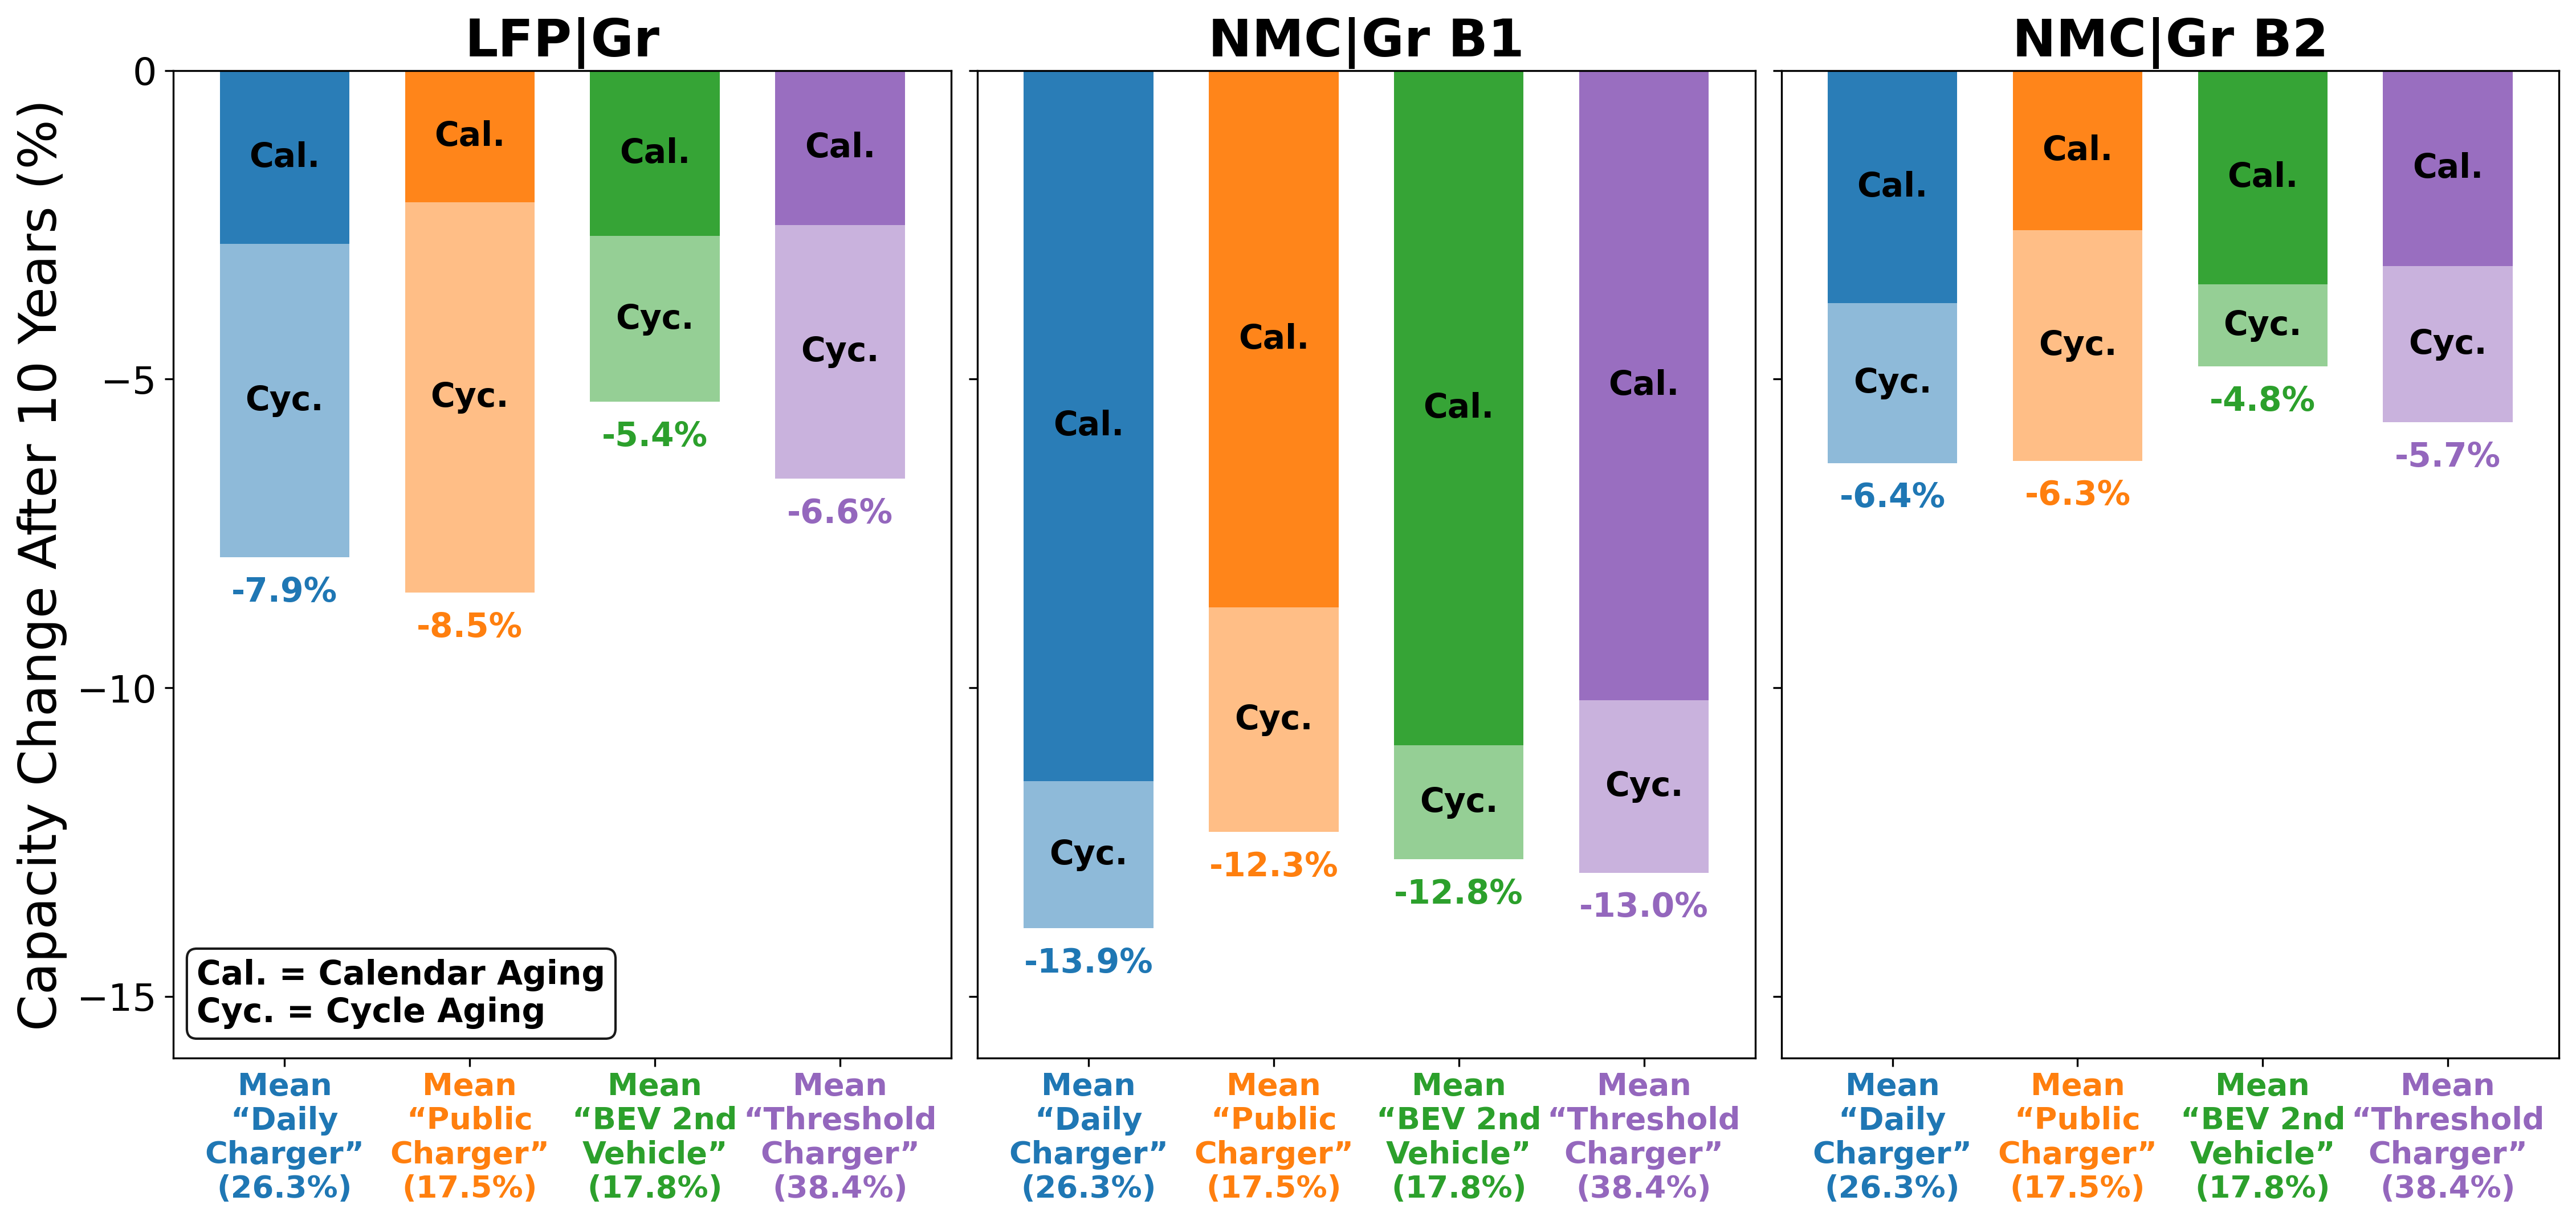

In [53]:
# Compute cluster sizes for x-axis labels
cluster_counts = results_df['cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(results_df) * 100).round(1)

# Profile names with line breaks as requested
cluster_display_names = {
    0: "Daily\nCharger",
    1: "Public\nCharger",
    2: "BEV 2nd\nVehicle",
    3: "Threshold\nCharger"
}

# Build x-axis label lines per cluster
x_label_lines = {}
for c in sorted(cluster_mapping.keys()):
    display = cluster_display_names[c]
    x_label_lines[c] = f'Mean\n\u201c{display}\u201d\n({cluster_pcts[c]}%)'

# Compute mean losses per cluster (as negative values for plotting)
mean_df = -results_df.drop(columns=['vehicle_id', 'cluster_profile']).groupby('cluster').mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 7), dpi=300, sharey=True)

for idx, chemistry in enumerate(chemistry_array):
    ax = axes[idx]

    cal_vals = mean_df[f'q_loss_cal_{chemistry}_10_years'].values
    total_vals = mean_df[f'q_loss_{chemistry}_10_years'].values

    x = np.arange(4)

    # Plot total loss (cycle + calendar) as lighter bars
    ax.bar(x, total_vals, color=colors, alpha=0.5, width=0.7)
    # Overlay calendar portion as darker bars
    ax.bar(x, cal_vals, color=colors, alpha=0.9, width=0.7)

    # Annotate abbreviated "Cal." and "Cyc." text on each bar
    for j in range(len(x)):
        cal_mid = cal_vals[j] / 2
        ax.text(x[j], cal_mid, 'Cal.', ha='center', va='center',
                fontsize=14, fontweight='bold', color='black')

        cyc_mid = cal_vals[j] + (total_vals[j] - cal_vals[j]) / 2
        ax.text(x[j], cyc_mid, 'Cyc.', ha='center', va='center',
                fontsize=14, fontweight='bold', color='black')

        ax.text(x[j], total_vals[j] - 0.3, f'{total_vals[j]:.1f}%',
                ha='center', va='top', fontsize=14, fontweight='bold',
                color=colors[j])

    ax.set_title(chemistry, fontsize=22, fontweight='bold')
    ax.set_xticks(x)
    ax.set_yticks([0, -5, -10, -15])
    ax.tick_params(axis='y', labelsize=16)
    ax.set_ylim([-16, 0])

    # Color each x-tick label to match its bar color (keep fontsize=12)
    tick_labels = [x_label_lines[c] for c in sorted(cluster_mapping.keys())]
    ax.set_xticklabels(tick_labels, fontsize=13, fontweight='bold')
    for tick_label, color in zip(ax.get_xticklabels(), colors):
        tick_label.set_color(color)

    ax.set_xlim(-0.6, 3.6)
    ax.tick_params(axis='x', pad=2)

axes[0].set_ylabel('Capacity Change After 10 Years (%)', fontsize=22)

# Add text-only legend for abbreviations on the left panel
axes[0].text(0.03, 0.03, 'Cal. = Calendar Aging\nCyc. = Cycle Aging',
             transform=axes[0].transAxes, fontsize=14, fontweight='bold',
             ha='left', va='bottom',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                       edgecolor='black', alpha=0.9))

fig.tight_layout(pad=0.2, w_pad=0.2)
fig.savefig('battery_degradation_vehicle_clusters.pdf', bbox_inches='tight')
plt.show()

## Supplementary Figure 1 (Baseline 10-Year Capacity Loss with Error Bars)

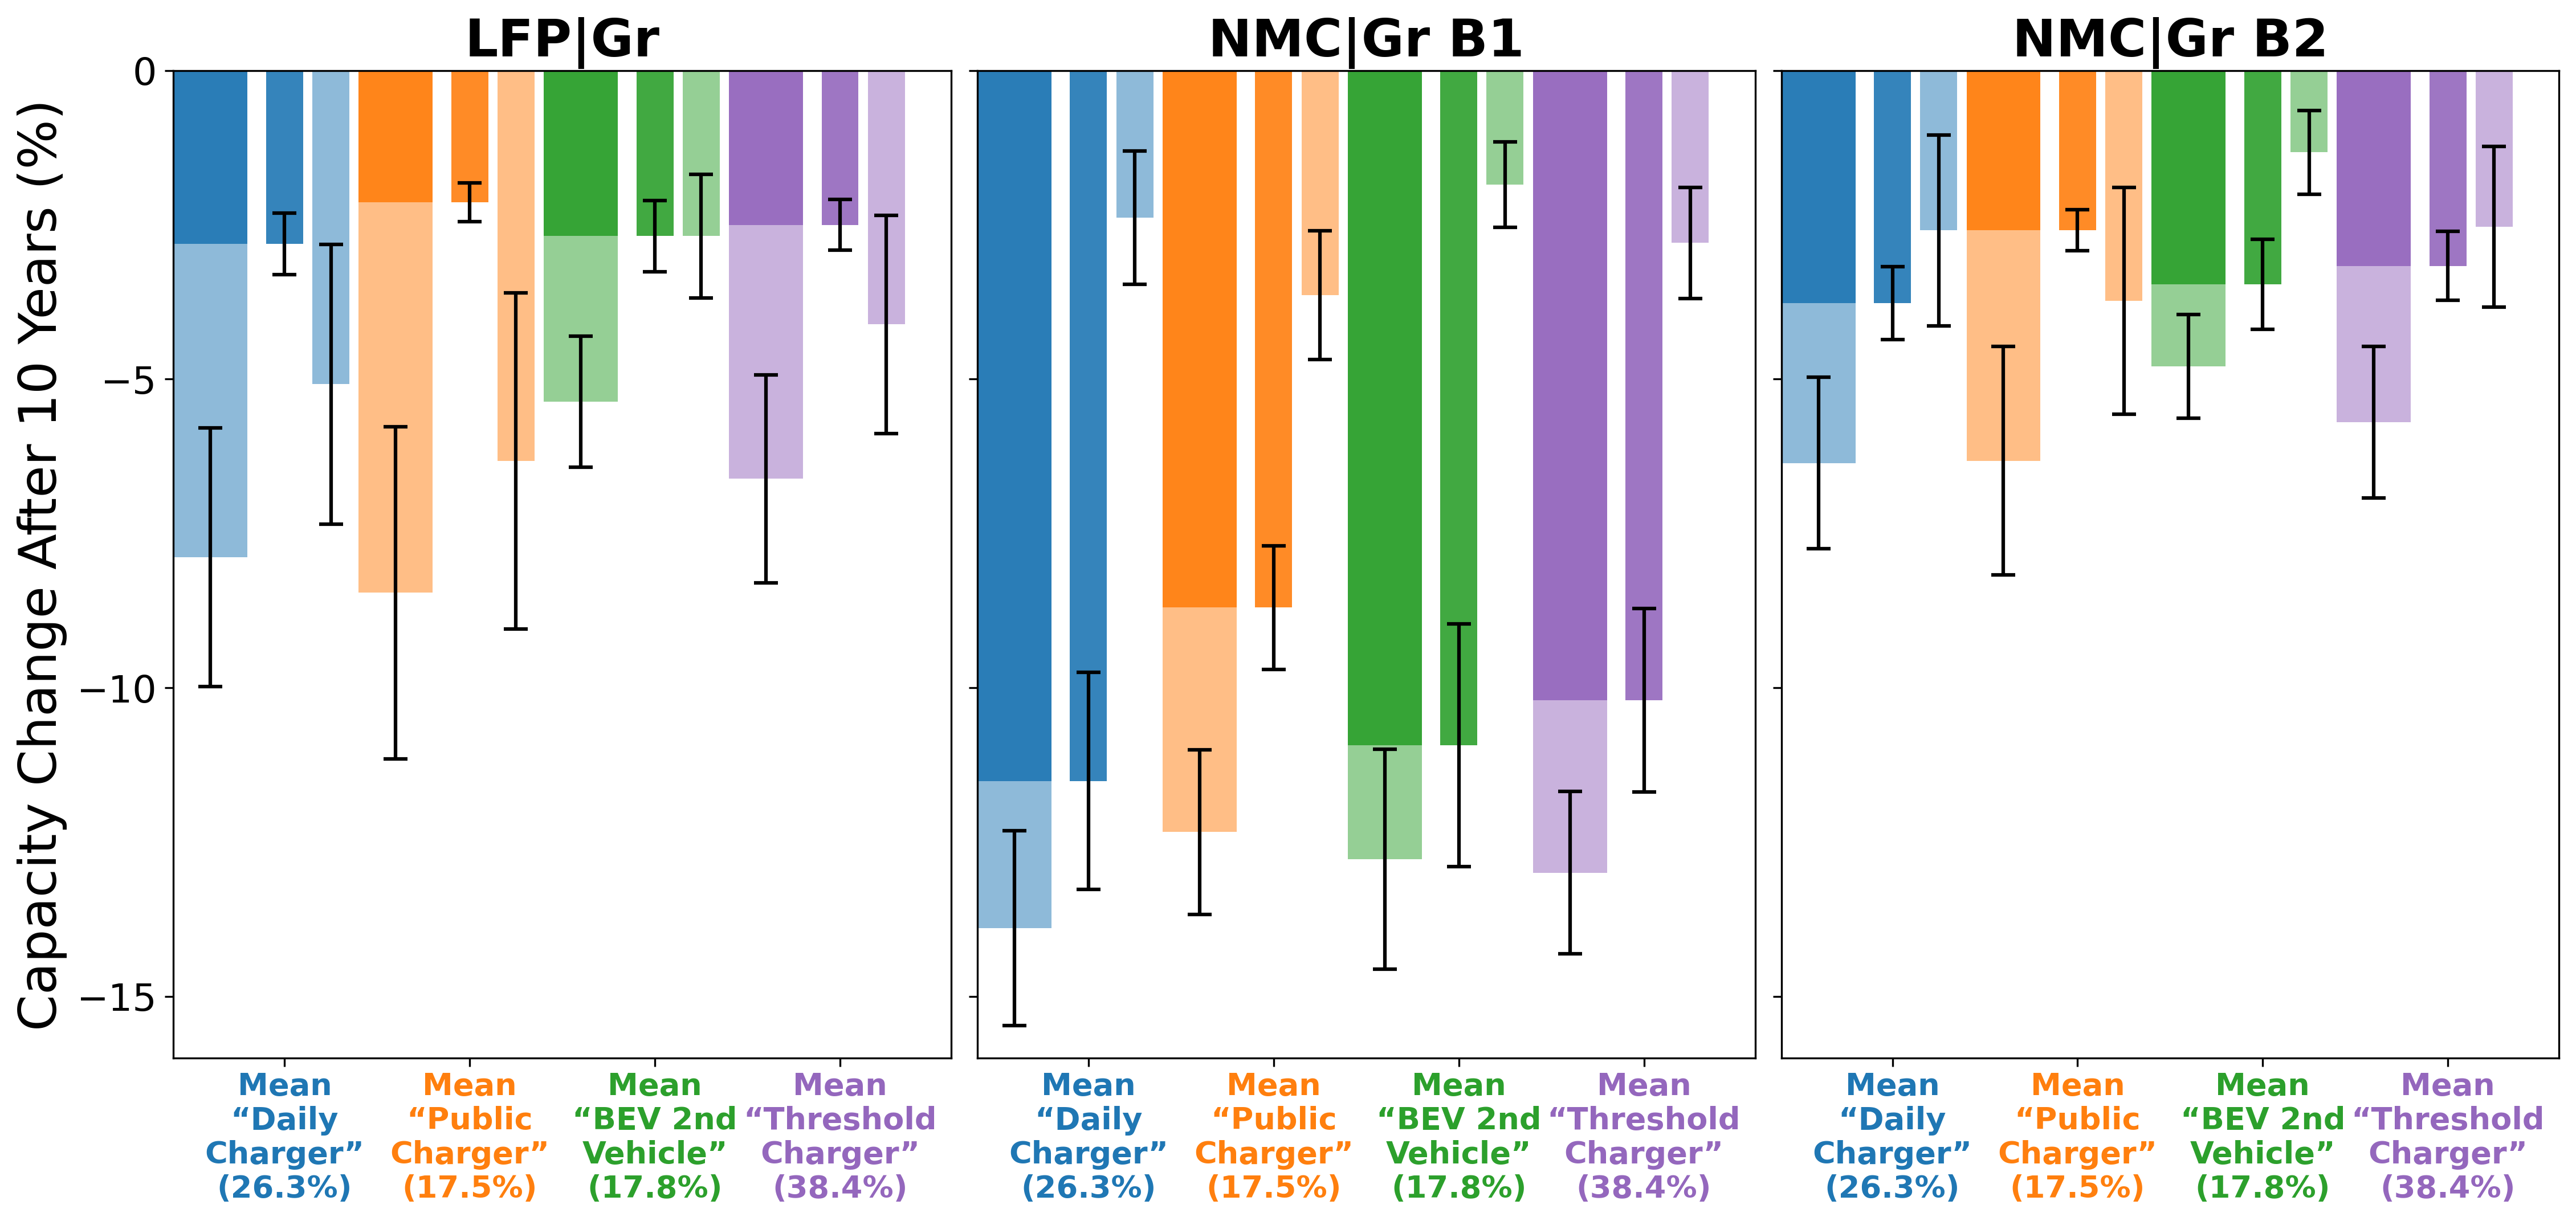

In [54]:
# Compute cluster sizes for x-axis labels
cluster_counts = results_df['cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(results_df) * 100).round(1)

# Profile names with line breaks
cluster_display_names = {
    0: "Daily\nCharger",
    1: "Public\nCharger",
    2: "BEV 2nd\nVehicle",
    3: "Threshold\nCharger"
}

# Build x-axis label lines per cluster
x_label_lines = {}
for c in sorted(cluster_mapping.keys()):
    display = cluster_display_names[c]
    x_label_lines[c] = f'Mean\n\u201c{display}\u201d\n({cluster_pcts[c]}%)'

# Compute mean and std losses per cluster (as negative values for plotting)
mean_df = -results_df.drop(columns=['vehicle_id', 'cluster_profile']).groupby('cluster').mean()
std_df = results_df.drop(columns=['vehicle_id', 'cluster_profile']).groupby('cluster').std()

fig, axes = plt.subplots(1, 3, figsize=(15, 7), dpi=300, sharey=True)

bar_width = 0.2

# Error bar styling
error_kw = dict(ecolor='black', elinewidth=1.5, capsize=5, capthick=1.5)

for idx, chemistry in enumerate(chemistry_array):
    ax = axes[idx]

    q_loss = mean_df[f'q_loss_{chemistry}_10_years'].values
    q_loss_cal = mean_df[f'q_loss_cal_{chemistry}_10_years'].values
    q_loss_cyc = mean_df[f'q_loss_cyc_{chemistry}_10_years'].values

    error_total = std_df[f'q_loss_{chemistry}_10_years'].values
    error_cal = std_df[f'q_loss_cal_{chemistry}_10_years'].values
    error_cyc = std_df[f'q_loss_cyc_{chemistry}_10_years'].values

    x = np.arange(4)

    # Wide stacked bar: cycle (alpha=0.5) as full total, calendar (alpha=0.9) overlaid
    ax.bar(x - 2 * bar_width, q_loss, width=2 * bar_width, color=colors, alpha=0.5)
    ax.bar(x - 2 * bar_width, q_loss_cal, width=2 * bar_width, color=colors, alpha=0.9)

    # Narrow calendar-only bar
    ax.bar(x, q_loss_cal, width=bar_width, color=colors, alpha=0.9)

    # Narrow cycle-only bar
    ax.bar(x + bar_width * 1.25, q_loss_cyc, width=bar_width, color=colors, alpha=0.5)

    # Error bars
    ax.errorbar(x - 2 * bar_width, q_loss, yerr=error_total, fmt='none', **error_kw)
    ax.errorbar(x, q_loss_cal, yerr=error_cal, fmt='none', **error_kw)
    ax.errorbar(x + bar_width * 1.25, q_loss_cyc, yerr=error_cyc, fmt='none', **error_kw)

    ax.set_title(chemistry, fontsize=22, fontweight='bold')
    ax.set_xticks(x)
    ax.set_yticks([0, -5, -10, -15])
    ax.tick_params(axis='y', labelsize=16)
    ax.set_ylim([-16, 0])

    # Colored x-tick labels
    tick_labels = [x_label_lines[c] for c in sorted(cluster_mapping.keys())]
    ax.set_xticklabels(tick_labels, fontsize=13, fontweight='bold')
    for tick_label, color in zip(ax.get_xticklabels(), colors):
        tick_label.set_color(color)

    ax.set_xlim(-0.6, 3.6)
    ax.tick_params(axis='x', pad=2)

axes[0].set_ylabel('Capacity Change After 10 Years (%)', fontsize=22)

fig.tight_layout(pad=0.2, w_pad=0.2)
fig.savefig('battery_degradation_vehicle_clusters_with_error.pdf', bbox_inches='tight')
plt.show()

## Figure 4 (Proportion of total capacity loss after 10 years attributed to calendar aging for all California vehicles)

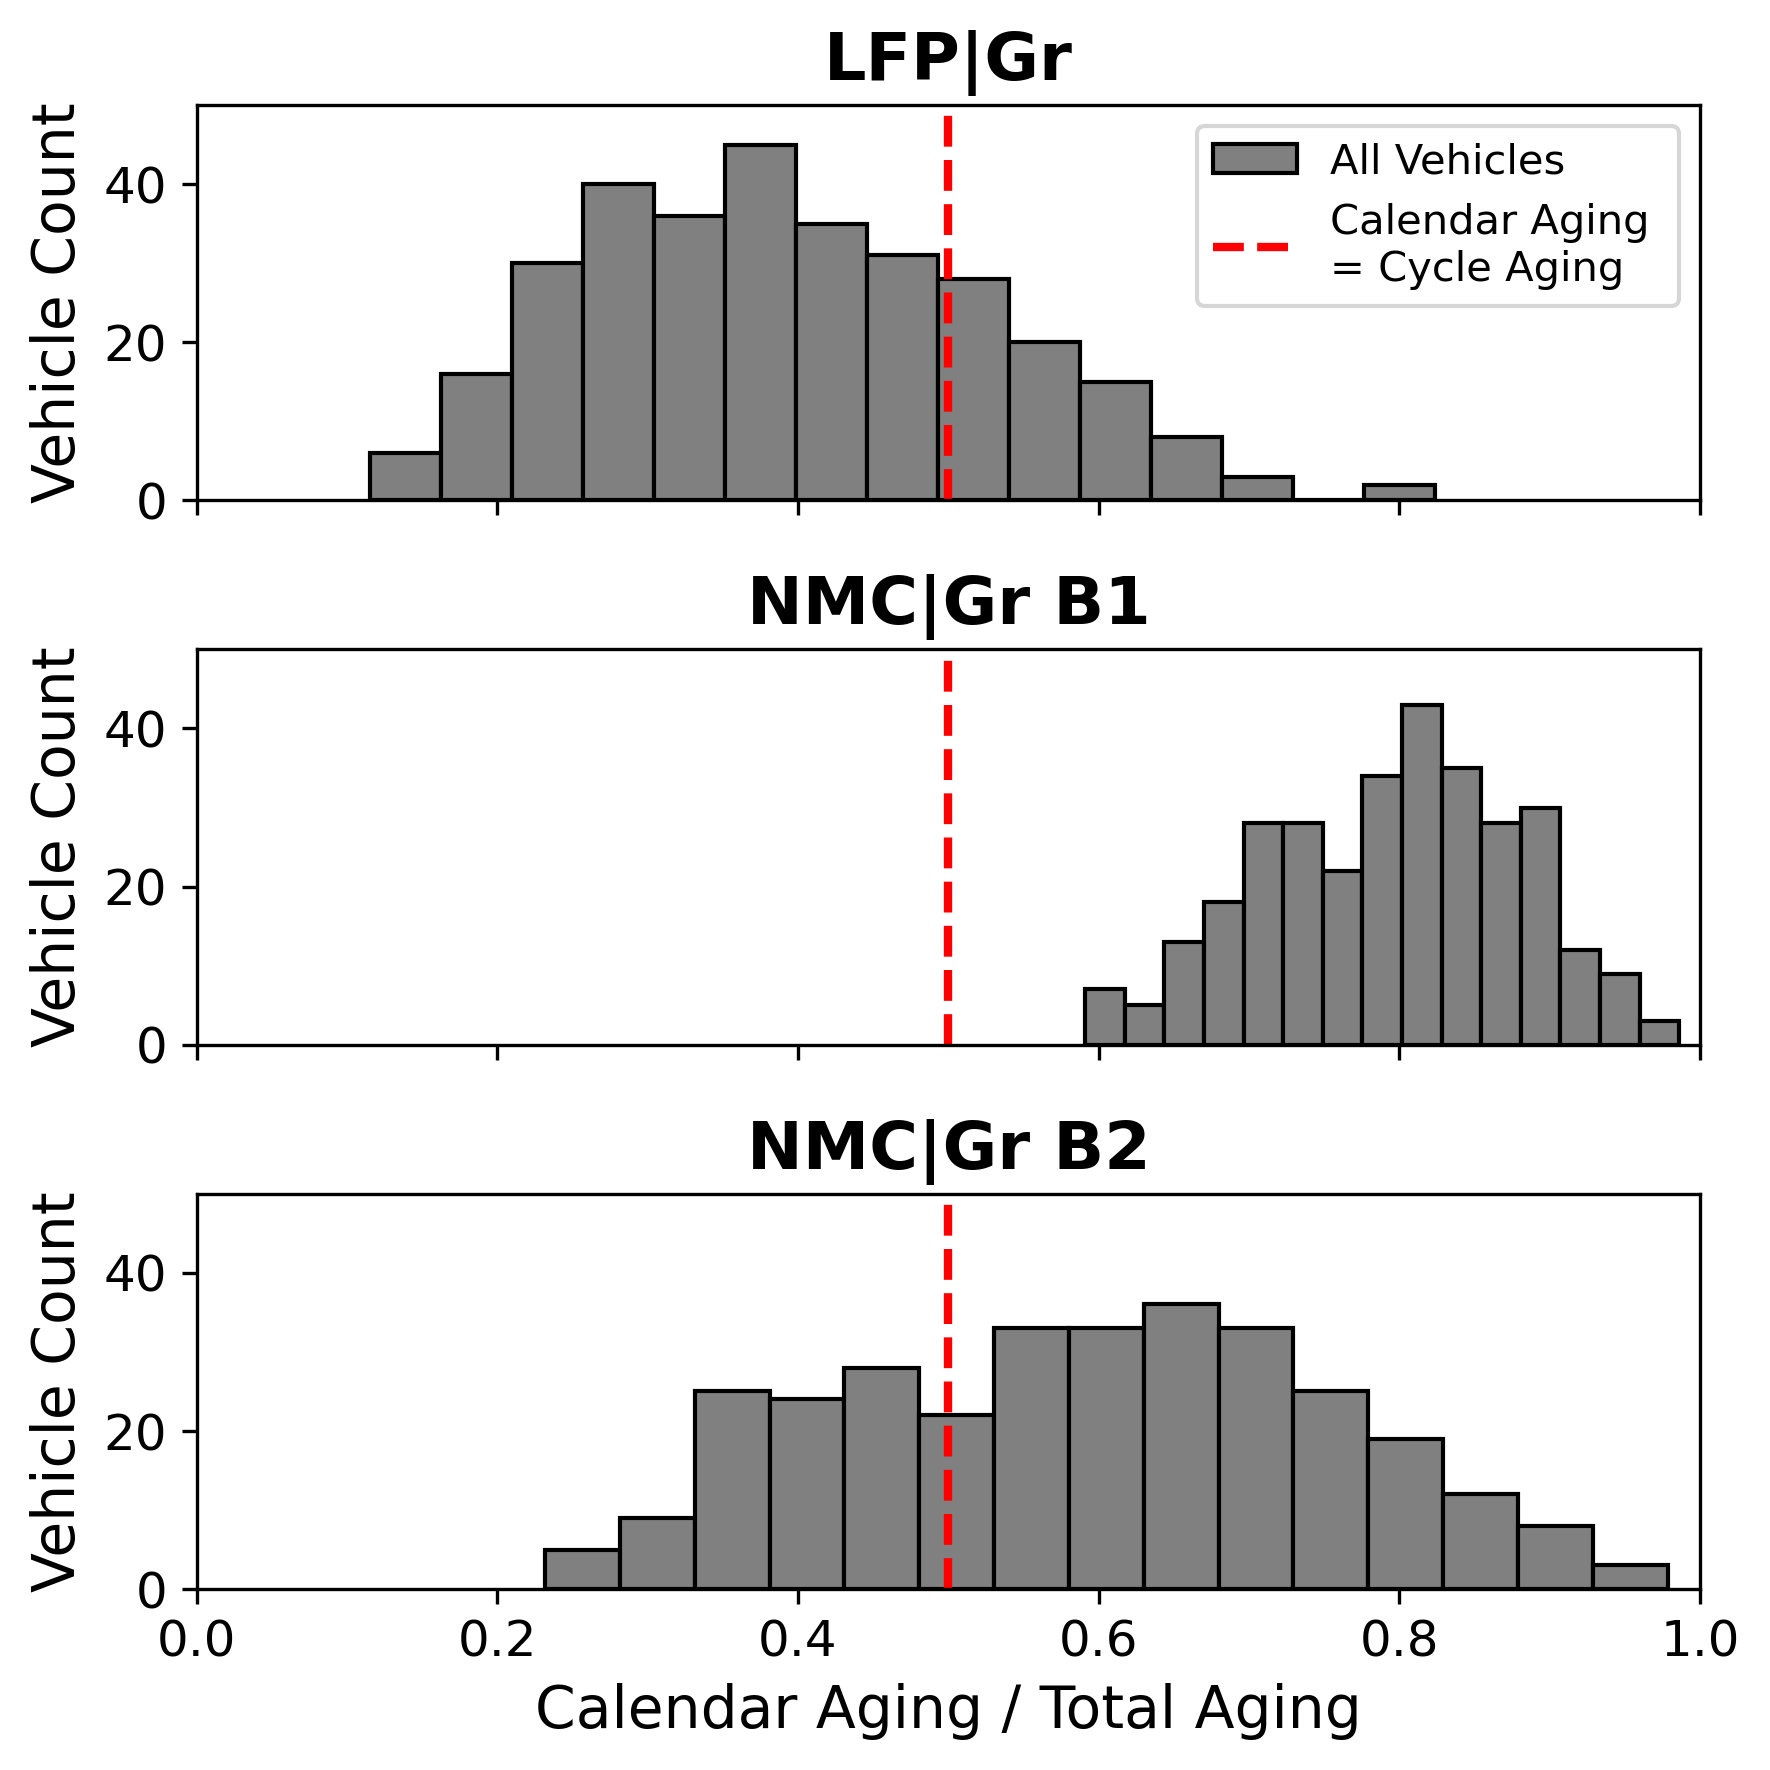

In [55]:
fig, ax = plt.subplots(3, 1, figsize=(6, 6), dpi=300, sharex=True)

for i, chemistry in enumerate(chemistry_array):
    ratio = results_df[f'q_loss_cal_{chemistry}_10_years'] / results_df[f'q_loss_{chemistry}_10_years']
    
    # Histogram
    ax[i].hist(ratio, color='grey', bins=15, edgecolor='black', label='All Vehicles')
    
    # Formatting
    ax[i].set_ylim(0, 50)
    ax[i].set_xlim(0, 1)
    ax[i].set_ylabel('Vehicle Count', fontsize=14)
    ax[i].set_title(chemistry, fontsize=16, fontweight='bold')
    
    # Vertical line for Calendar = Cycle parity
    ax[i].axvline(0.5, color='red', linestyle='--', linewidth=2, label='Calendar Aging \n= Cycle Aging')
    ax[i].tick_params(labelsize=12)

ax[-1].set_xlabel('Calendar Aging / Total Aging', fontsize=14)
ax[0].legend(fontsize=10)
fig.tight_layout()
plt.show()

# Figure 5

In [58]:
def confidence_interval_95(x):
    n = len(x)
    mean = x.mean()
    se = x.std() / np.sqrt(n)
    ci = st.t.interval(0.95, df=n-1, loc=mean, scale=se)
    return ci

In [67]:
results_df

,vehicle_id,cluster,q_loss_LFP|Gr_10_years,q_loss_cyc_LFP|Gr_10_years,q_loss_cal_LFP|Gr_10_years,q_loss_NMC|Gr B1_10_years,q_loss_cyc_NMC|Gr B1_10_years,q_loss_cal_NMC|Gr B1_10_years,q_loss_NMC|Gr B2_10_years,q_loss_cyc_NMC|Gr B2_10_years,...,delta_q_loss_cyc_LFP|Gr_10_years,delta_q_loss_cal_LFP|Gr_10_years,delta_q_loss_NMC|Gr B1_10_years,delta_q_loss_cyc_NMC|Gr B1_10_years,delta_q_loss_cal_NMC|Gr B1_10_years,delta_q_loss_NMC|Gr B2_10_years,delta_q_loss_cyc_NMC|Gr B2_10_years,delta_q_loss_cal_NMC|Gr B2_10_years,V2G_kwh_10_years,cluster_profile
0,0,0,6.846279,4.002871,2.843409,13.949890,2.197217,11.752672,5.879810,2.059128,...,-0.567448,0.109137,0.342753,-0.119793,0.462546,-0.122799,-0.316951,0.194152,10821.36,Daily Charger
1,1,3,4.673586,2.752955,1.920631,10.744970,2.735554,8.009415,4.277929,1.925591,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Threshold Charger
2,2,1,5.510617,3.082581,2.428036,11.672900,2.083842,9.589058,4.247546,1.402647,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
3,3,0,9.506368,7.214909,2.291459,8.965488,2.407599,6.557889,4.866640,2.103478,...,-0.408039,0.035142,0.167620,0.004523,0.163097,-0.099939,-0.170969,0.071030,7053.60,Daily Charger
4,4,3,4.392786,1.984613,2.408174,11.813082,1.996731,9.816351,4.225082,1.223307,...,0.016273,0.012918,0.112670,0.058687,0.053983,0.060643,0.039387,0.021256,28.56,Threshold Charger
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,310,2,5.095129,2.216411,2.878718,12.558043,1.529224,11.028819,4.229954,0.800333,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,BEV 2nd vehicle
311,311,1,4.408061,2.257766,2.150295,10.904760,2.422791,8.481969,3.742655,1.313861,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
312,312,0,7.481869,4.410115,3.071754,14.775629,2.520803,12.254826,6.332286,2.406093,...,-0.787757,0.236041,0.781463,-0.183725,0.965188,-0.091834,-0.489162,0.397328,14905.92,Daily Charger
313,313,3,5.451682,3.220131,2.231551,11.864274,2.383082,9.481192,4.847518,1.886269,...,-0.151935,0.057785,0.282656,0.030798,0.251858,0.061807,-0.040324,0.102131,2735.16,Threshold Charger


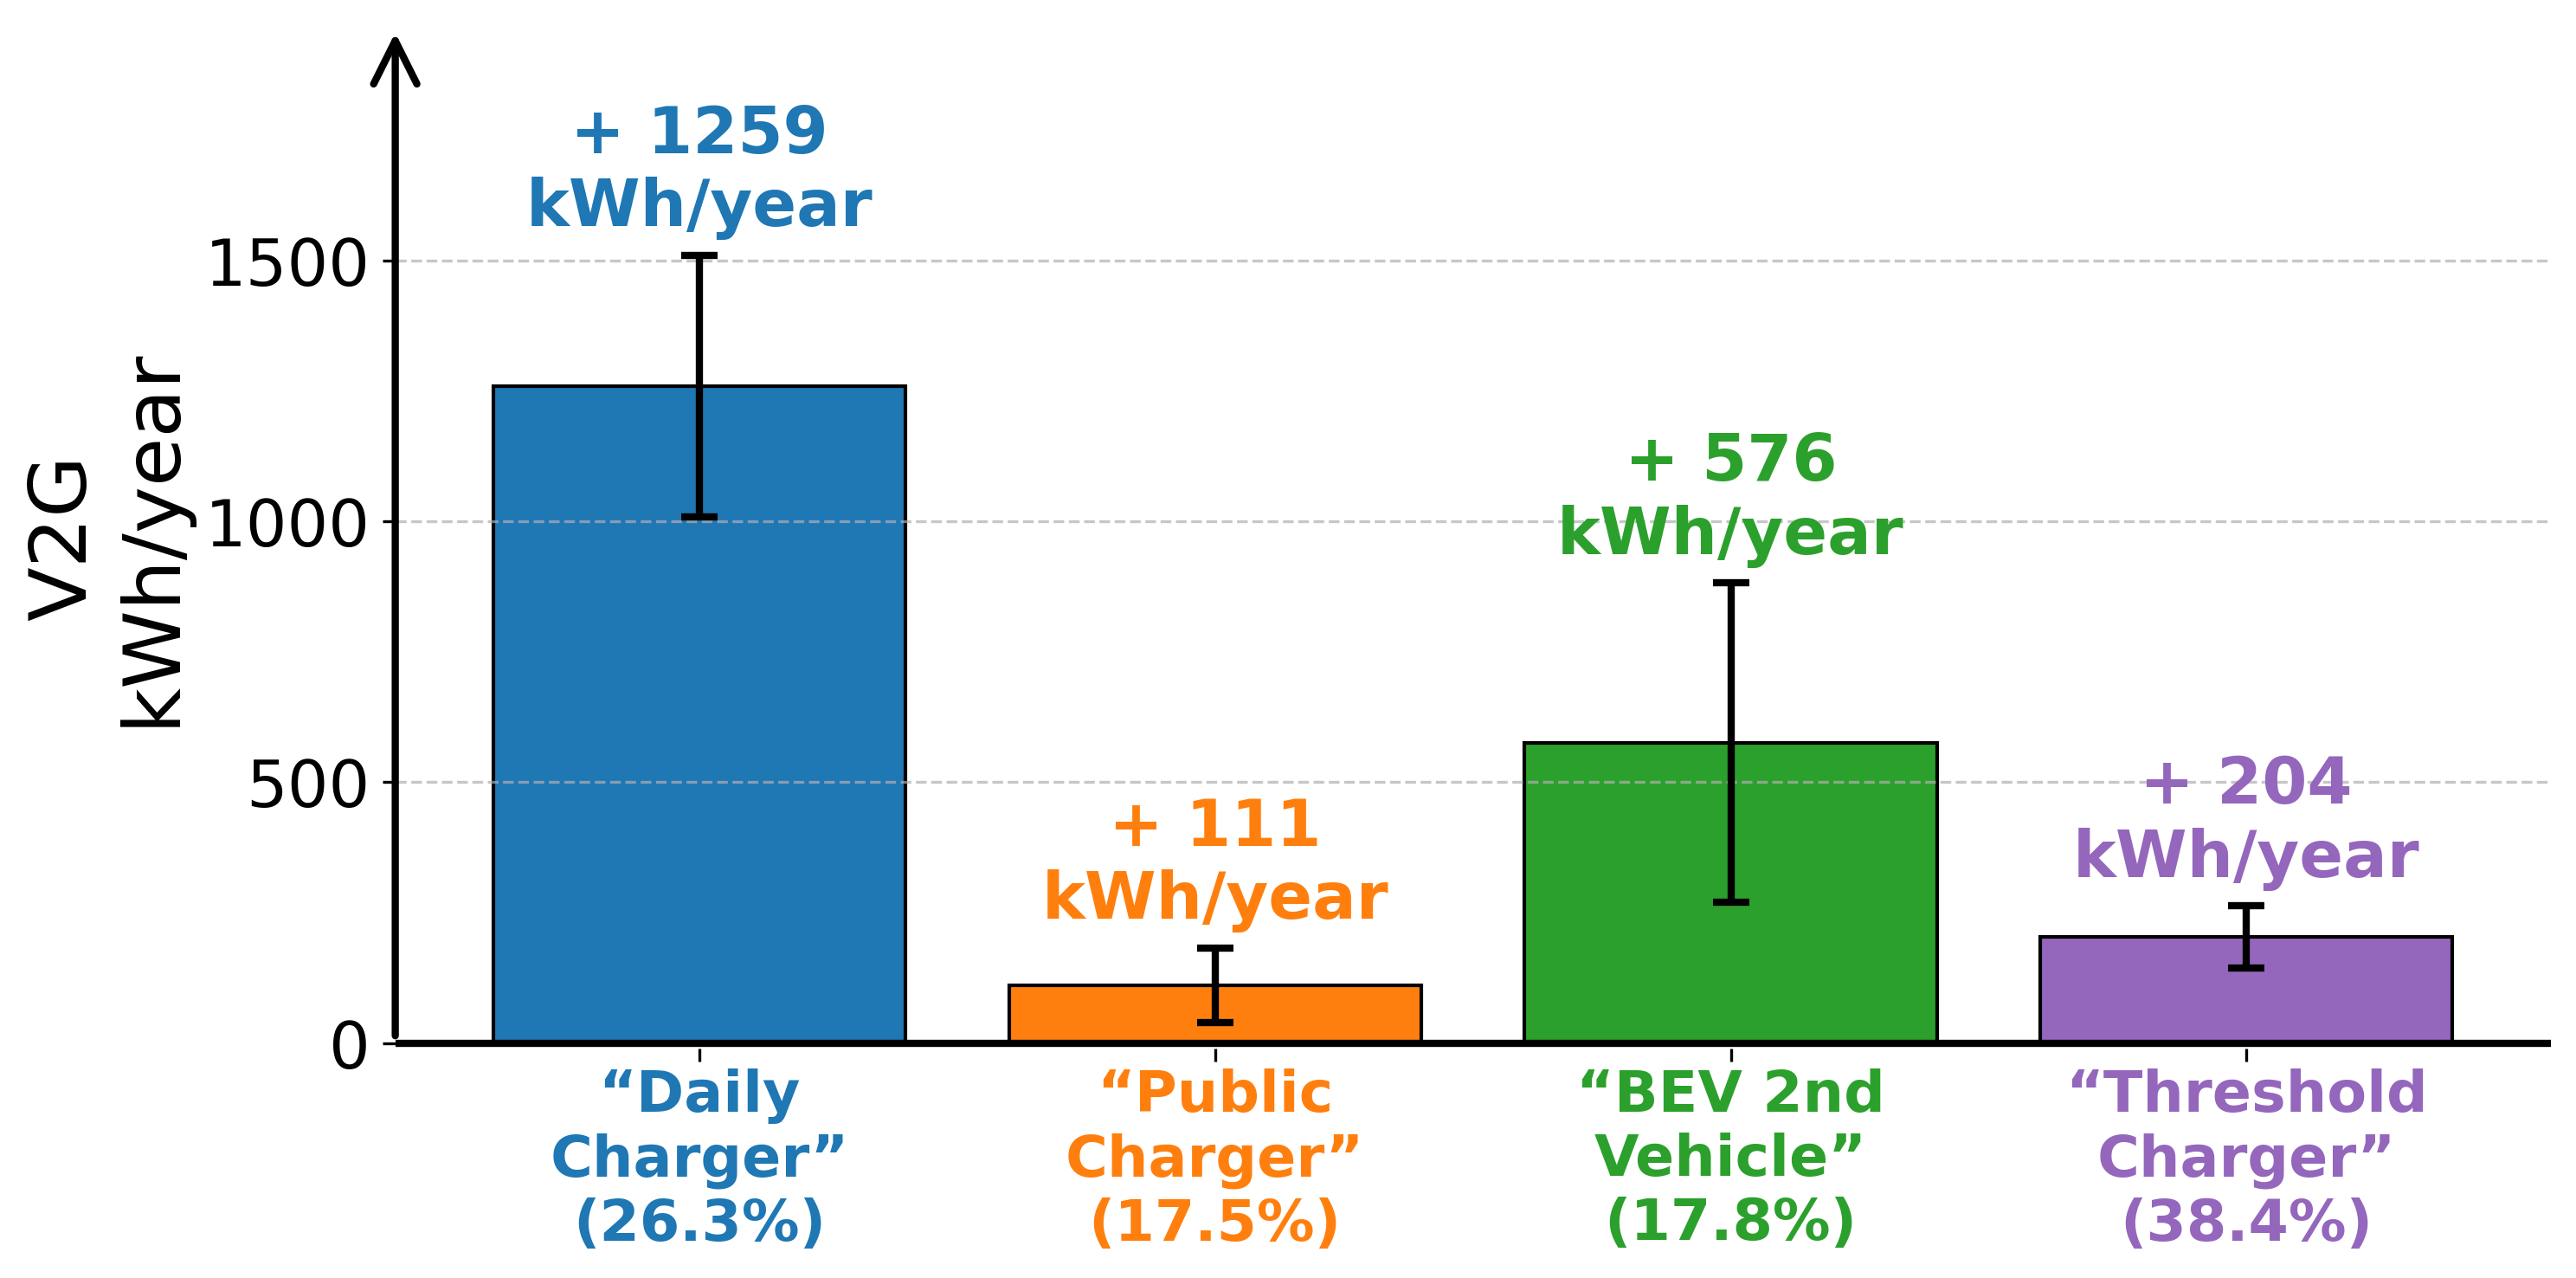

In [71]:
# Cluster display names and percentages
cluster_counts = results_df['cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(results_df) * 100).round(1)

pr_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

pr_cluster_display = {
    0: "Daily\nCharger",
    1: "Public\nCharger",
    2: "BEV 2nd\nVehicle",
    3: "Threshold\nCharger"
}

pr_x_labels = {}
for c in sorted(cluster_mapping.keys()):
    display = pr_cluster_display[c]
    pr_x_labels[c] = f'\u201c{display}\u201d\n({cluster_pcts[c]}%)'

results_df['V2G kwh per year'] = results_df['V2G_kwh_10_years']/10

# Compute grouped stats with confidence intervals
pr_sorted_df = (results_df.drop(columns=['vehicle_id', 'cluster_profile'])
                .groupby('cluster', group_keys=False)).agg(['mean', 'std', 'median', confidence_interval_95])

data_column = 'V2G kwh per year'
means = pr_sorted_df[(data_column, 'mean')].values
ci_intervals = pr_sorted_df[(data_column, 'confidence_interval_95')]

lower_bounds = ci_intervals.apply(lambda x: x[0]).values
upper_bounds = ci_intervals.apply(lambda x: x[1]).values
lower_error = means - lower_bounds
upper_error = upper_bounds - means
yerr = [lower_error, upper_error]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

x = np.arange(4)

# Plot bars
bars = ax.bar(x, means, color=pr_colors, width=0.8,
              edgecolor='black', linewidth=1, yerr=yerr, capsize=5,
              error_kw={'elinewidth': 2, 'capthick': 2, 'ecolor': 'black'})

# Value annotations above error bars
for j in range(len(x)):
    val = means[j]
    anchor = val + upper_error[j]
    ax.text(x[j], anchor + 30, f'+ {val:.0f}\nkWh/year',
            ha='center', va='bottom', fontsize=18, fontweight='bold',
            color=pr_colors[j])

# Styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.axhline(0, color='black', linewidth=2)
ax.tick_params(axis='y', labelsize=18)
ax.set_ylim([-10, 1500 + 0.3 * 1500])

# Arrow on y-axis
ax.annotate('', xy=(0, 1500 + 0.3 * 1500), xytext=(0, 0),
            xycoords=('axes fraction', 'data'), textcoords=('axes fraction', 'data'),
            arrowprops={'arrowstyle': '->', 'color': 'black', 'linewidth': 2, 'mutation_scale': 30})

ax.set_ylabel('V2G\nkWh/year', fontsize=22)

# Colored x-tick labels
ax.set_xticks(x)
tick_labels = [pr_x_labels[c] for c in sorted(cluster_mapping.keys())]
ax.set_xticklabels(tick_labels, fontsize=16, fontweight='bold')
for tick_label, color in zip(ax.get_xticklabels(), pr_colors):
    tick_label.set_color(color)
ax.tick_params(axis='x', pad=2)

fig.tight_layout(pad=1)
fig.savefig('participation_rates.pdf', bbox_inches='tight')
plt.show()

In [ ]:
## Fleet-wide average V2G participation
data_column = 'V2G kwh per year'
means = pr_sorted_df[(data_column, 'mean')].values
fleet_avg = sum(means * (cluster_counts / sum(cluster_counts)))
print(f"Fleet-wide average V2G participation: {fleet_avg:.0f} kWh/yr per BEV")

# Figure 6

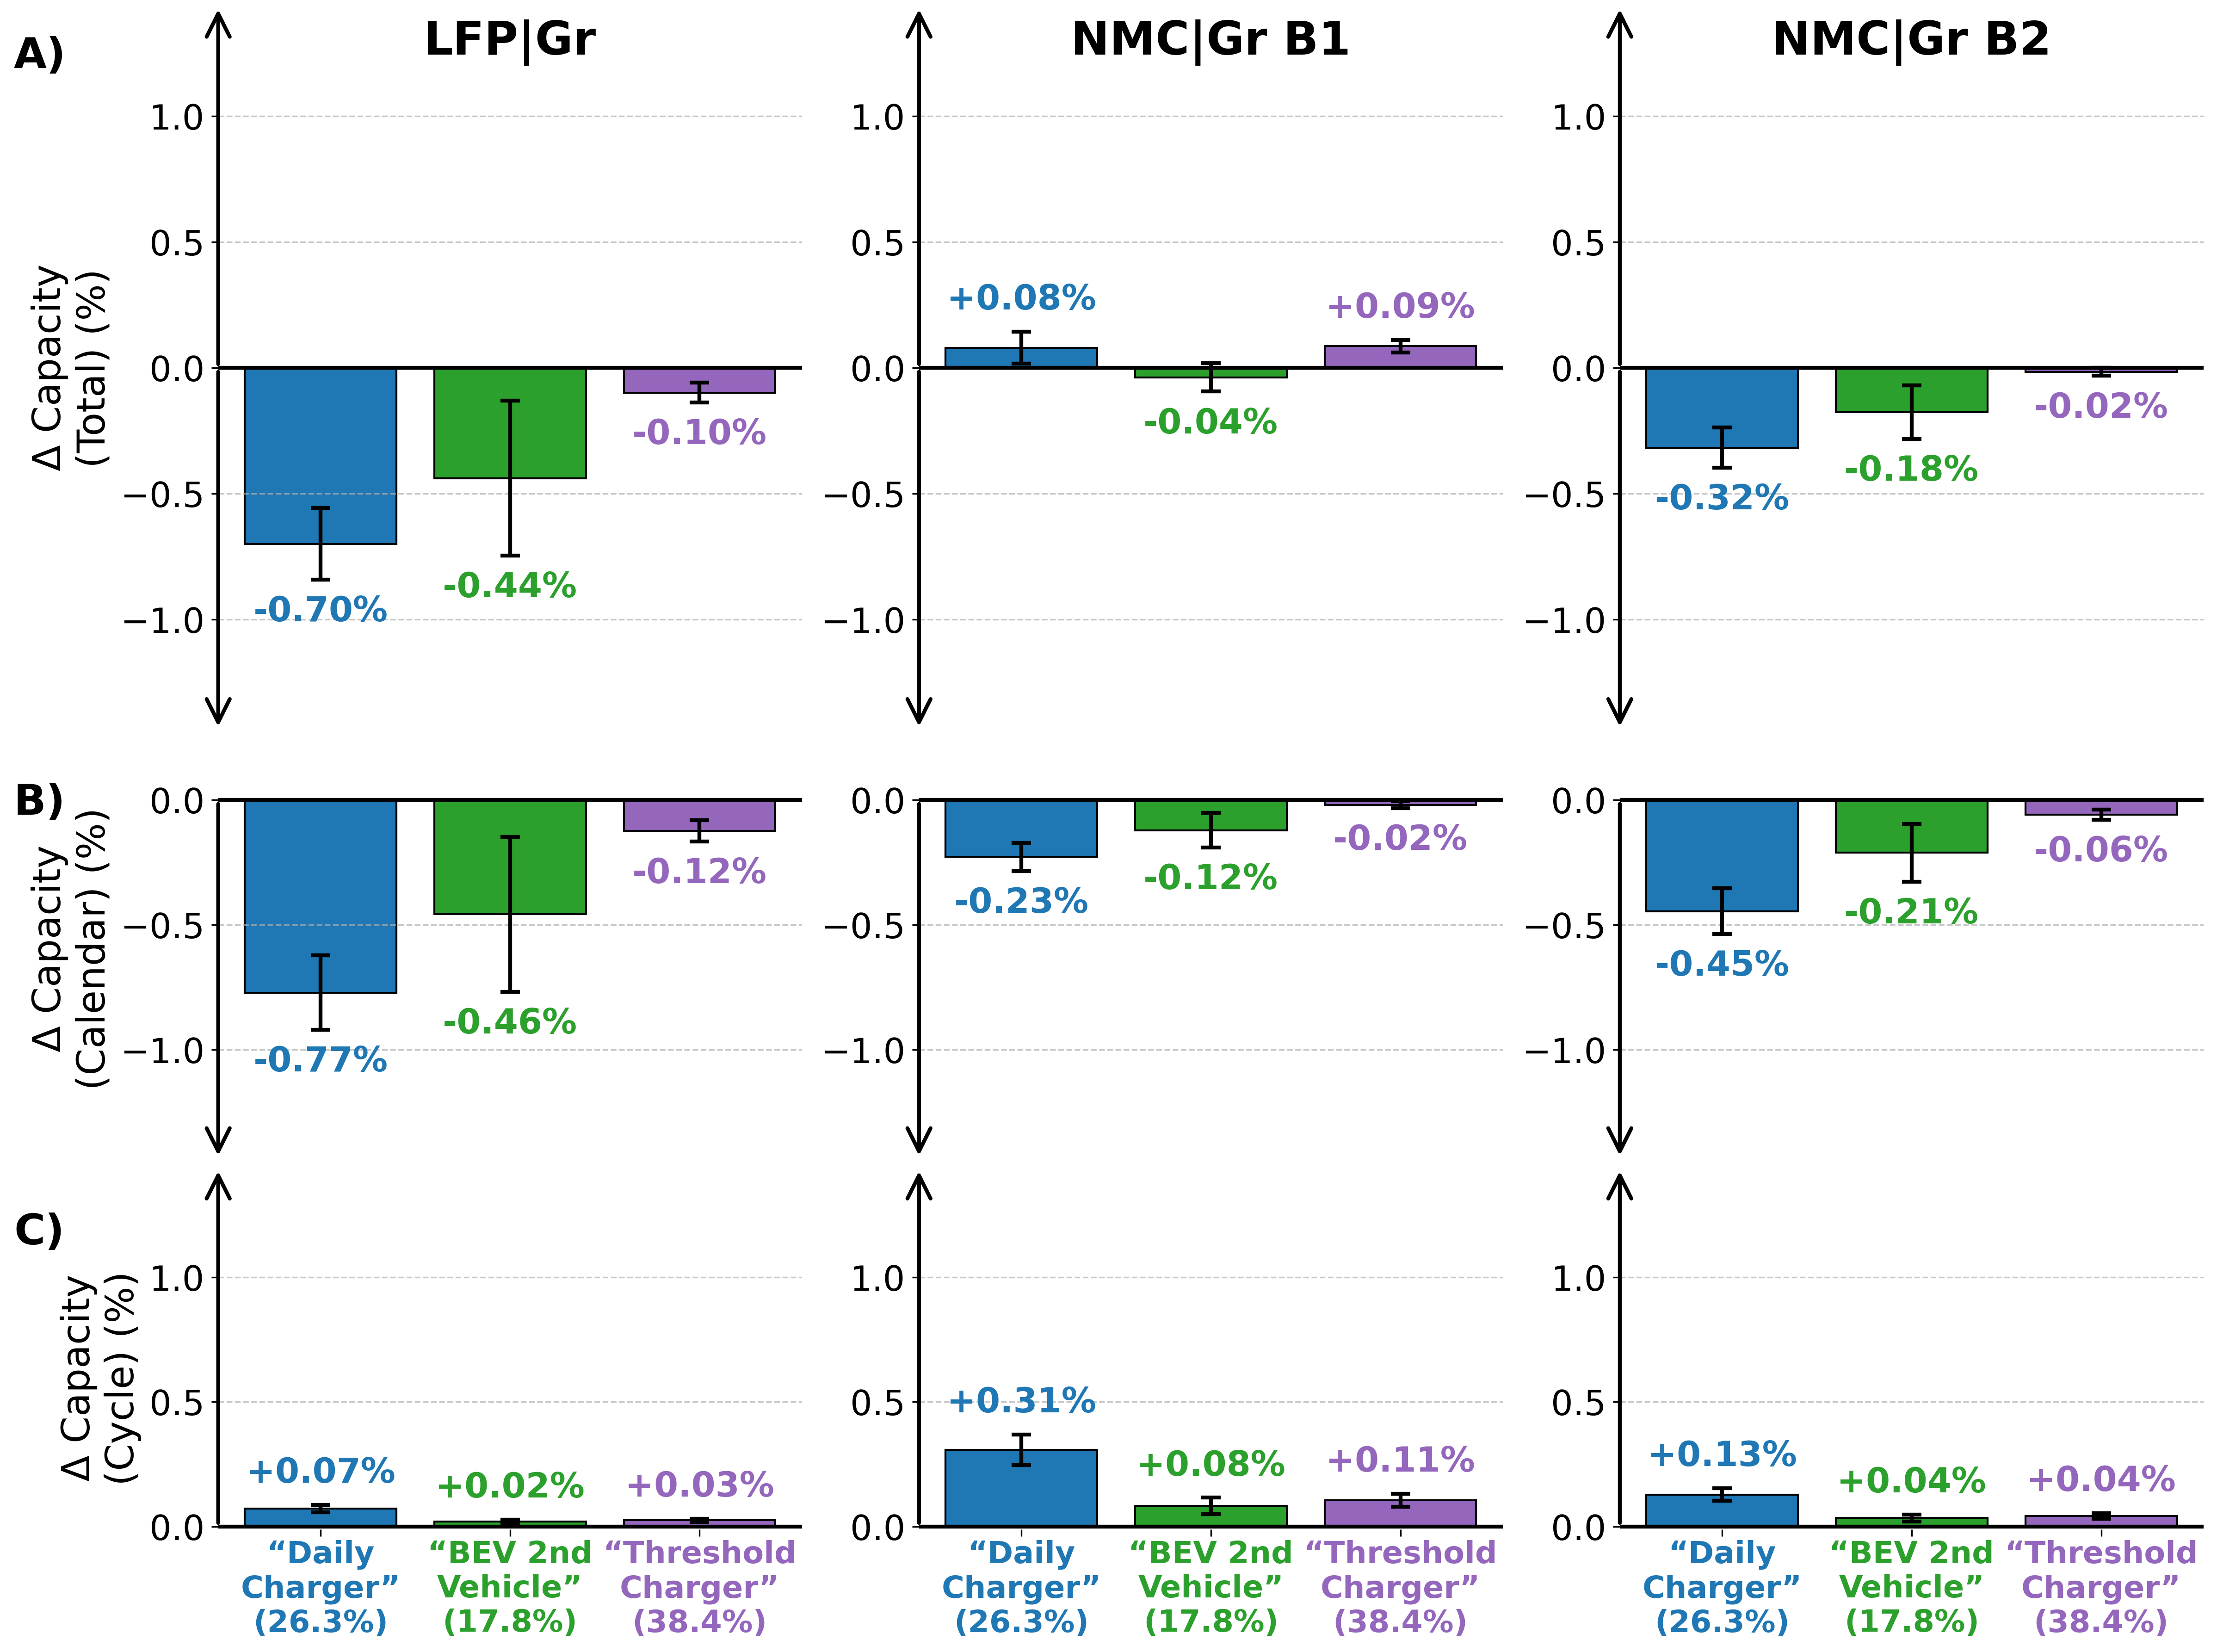

In [64]:
# Clusters to show (exclude Public Charger / cluster 1)
v2g_clusters = [0, 2, 3]
v2g_colors = ['#1f77b4', '#2ca02c', '#9467bd']

# Cluster display names and percentages
cluster_counts = results_df['cluster'].value_counts().sort_index()
cluster_pcts = (cluster_counts / len(results_df) * 100).round(1)

v2g_cluster_display = {
    0: "Daily\nCharger",
    2: "BEV 2nd\nVehicle",
    3: "Threshold\nCharger"
}

v2g_x_labels = {}
for c in v2g_clusters:
    display = v2g_cluster_display[c]
    v2g_x_labels[c] = f'\u201c{display}\u201d\n({cluster_pcts[c]}%)'

# Compute grouped stats with confidence intervals
sorted_df = (results_df.drop(columns=['vehicle_id', 'cluster_profile'])
             .groupby('cluster', group_keys=False)).agg(['mean', 'std', 'median', confidence_interval_95])

# Row config matching Figure 5/6 column-to-label mapping:
#   Row A (Total):    delta_q_loss_{chem}
#   Row B (Calendar): delta_q_loss_cyc_{chem}  (follows Figure 5/6 i=2)
#   Row C (Cycle):    delta_q_loss_cal_{chem}  (follows Figure 5/6 i=3)
row_config = [
    ('delta_q_loss_{chem}_10_years', '$\\Delta$ Capacity\n(Total) (%)', (-1.2, 1.2), ['up', 'down']),
    ('delta_q_loss_cyc_{chem}_10_years', '$\\Delta$ Capacity\n(Calendar) (%)', (-1.2, 0.01), ['down']),
    ('delta_q_loss_cal_{chem}_10_years', '$\\Delta$ Capacity\n(Cycle) (%)', (-0.01, 1.2), ['up']),
]

fig = plt.figure(figsize=(16, 12), dpi=300)
gs = gridspec.GridSpec(3, 3, height_ratios=[2, 1, 1])
axes = [[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(3)]

for col_idx, chemistry in enumerate(chemistry_array):
    for row_idx, (col_template, ylabel, ylim, arrow_dirs) in enumerate(row_config):
        ax = axes[row_idx][col_idx]
        data_column = col_template.format(chem=chemistry)

        # Extract means and confidence intervals for the 3 clusters
        means = sorted_df[(data_column, 'mean')].loc[v2g_clusters].values
        ci_intervals = sorted_df[(data_column, 'confidence_interval_95')].loc[v2g_clusters]

        lower_bounds = ci_intervals.apply(lambda x: x[0]).values
        upper_bounds = ci_intervals.apply(lambda x: x[1]).values
        lower_error = means - lower_bounds
        upper_error = upper_bounds - means
        yerr = [lower_error, upper_error]

        x = np.arange(len(v2g_clusters))

        # Plot bars
        bars = ax.bar(x, means, color=v2g_colors, width=0.8,
                       edgecolor='black', linewidth=1, yerr=yerr, capsize=5,
                       error_kw={'elinewidth': 2, 'capthick': 2, 'ecolor': 'black'})

        # Value annotations — position beyond error bar tip with spacing
        for j in range(len(x)):
            val = means[j]
            sign = '+' if val >= 0 else ''
            if val >= 0:
                anchor = val + upper_error[j]
                ax.text(x[j], anchor + 0.06, f'{sign}{val:.2f}%',
                        ha='center', va='bottom', fontsize=18, fontweight='bold',
                        color=v2g_colors[j])
            else:
                anchor = val - lower_error[j]
                ax.text(x[j], anchor - 0.06, f'{sign}{val:.2f}%',
                        ha='center', va='top', fontsize=18, fontweight='bold',
                        color=v2g_colors[j])

        # Styling
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.axhline(0, color='black', linewidth=2)
        ax.tick_params(axis='y', labelsize=18)
        ax.set_ylim(ylim)

        # Arrows on y-axis
        for arrow_dir in arrow_dirs:
            if arrow_dir == 'up':
                ax.annotate('', xy=(0, ylim[1] + abs(ylim[1]) * 0.2), xytext=(0, 0),
                            xycoords=('axes fraction', 'data'), textcoords=('axes fraction', 'data'),
                            arrowprops={'arrowstyle': '->', 'color': 'black', 'linewidth': 2, 'mutation_scale': 30})
            elif arrow_dir == 'down':
                ax.annotate('', xy=(0, ylim[0] - abs(ylim[0]) * 0.2), xytext=(0, 0),
                            xycoords=('axes fraction', 'data'), textcoords=('axes fraction', 'data'),
                            arrowprops={'arrowstyle': '->', 'color': 'black', 'linewidth': 2, 'mutation_scale': 30})

        # Title on top row only
        if row_idx == 0:
            ax.set_title(chemistry, fontsize=24, fontweight='bold')

        # Y-axis label on left column only
        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=20)

        # Panel labels A), B), C) on left column
        if col_idx == 0:
            label = ['A)', 'B)', 'C)'][row_idx]
            ax.text(-0.35, 1.05, label, transform=ax.transAxes,
                    fontsize=22, fontweight='bold', va='top')

        # X-tick labels only on bottom row, colored
        if row_idx == 2:
            ax.set_xticks(x)
            tick_labels = [v2g_x_labels[c] for c in v2g_clusters]
            ax.set_xticklabels(tick_labels, fontsize=16, fontweight='bold')
            for tick_label, color in zip(ax.get_xticklabels(), v2g_colors):
                tick_label.set_color(color)
            ax.tick_params(axis='x', pad=2)
        else:
            ax.set_xticks([])

fig.tight_layout(pad=1)
fig.savefig('v2g_battery_degradation_vehicle_clusters.pdf', bbox_inches='tight')
plt.show()

# Supplementary Note 5 Figures

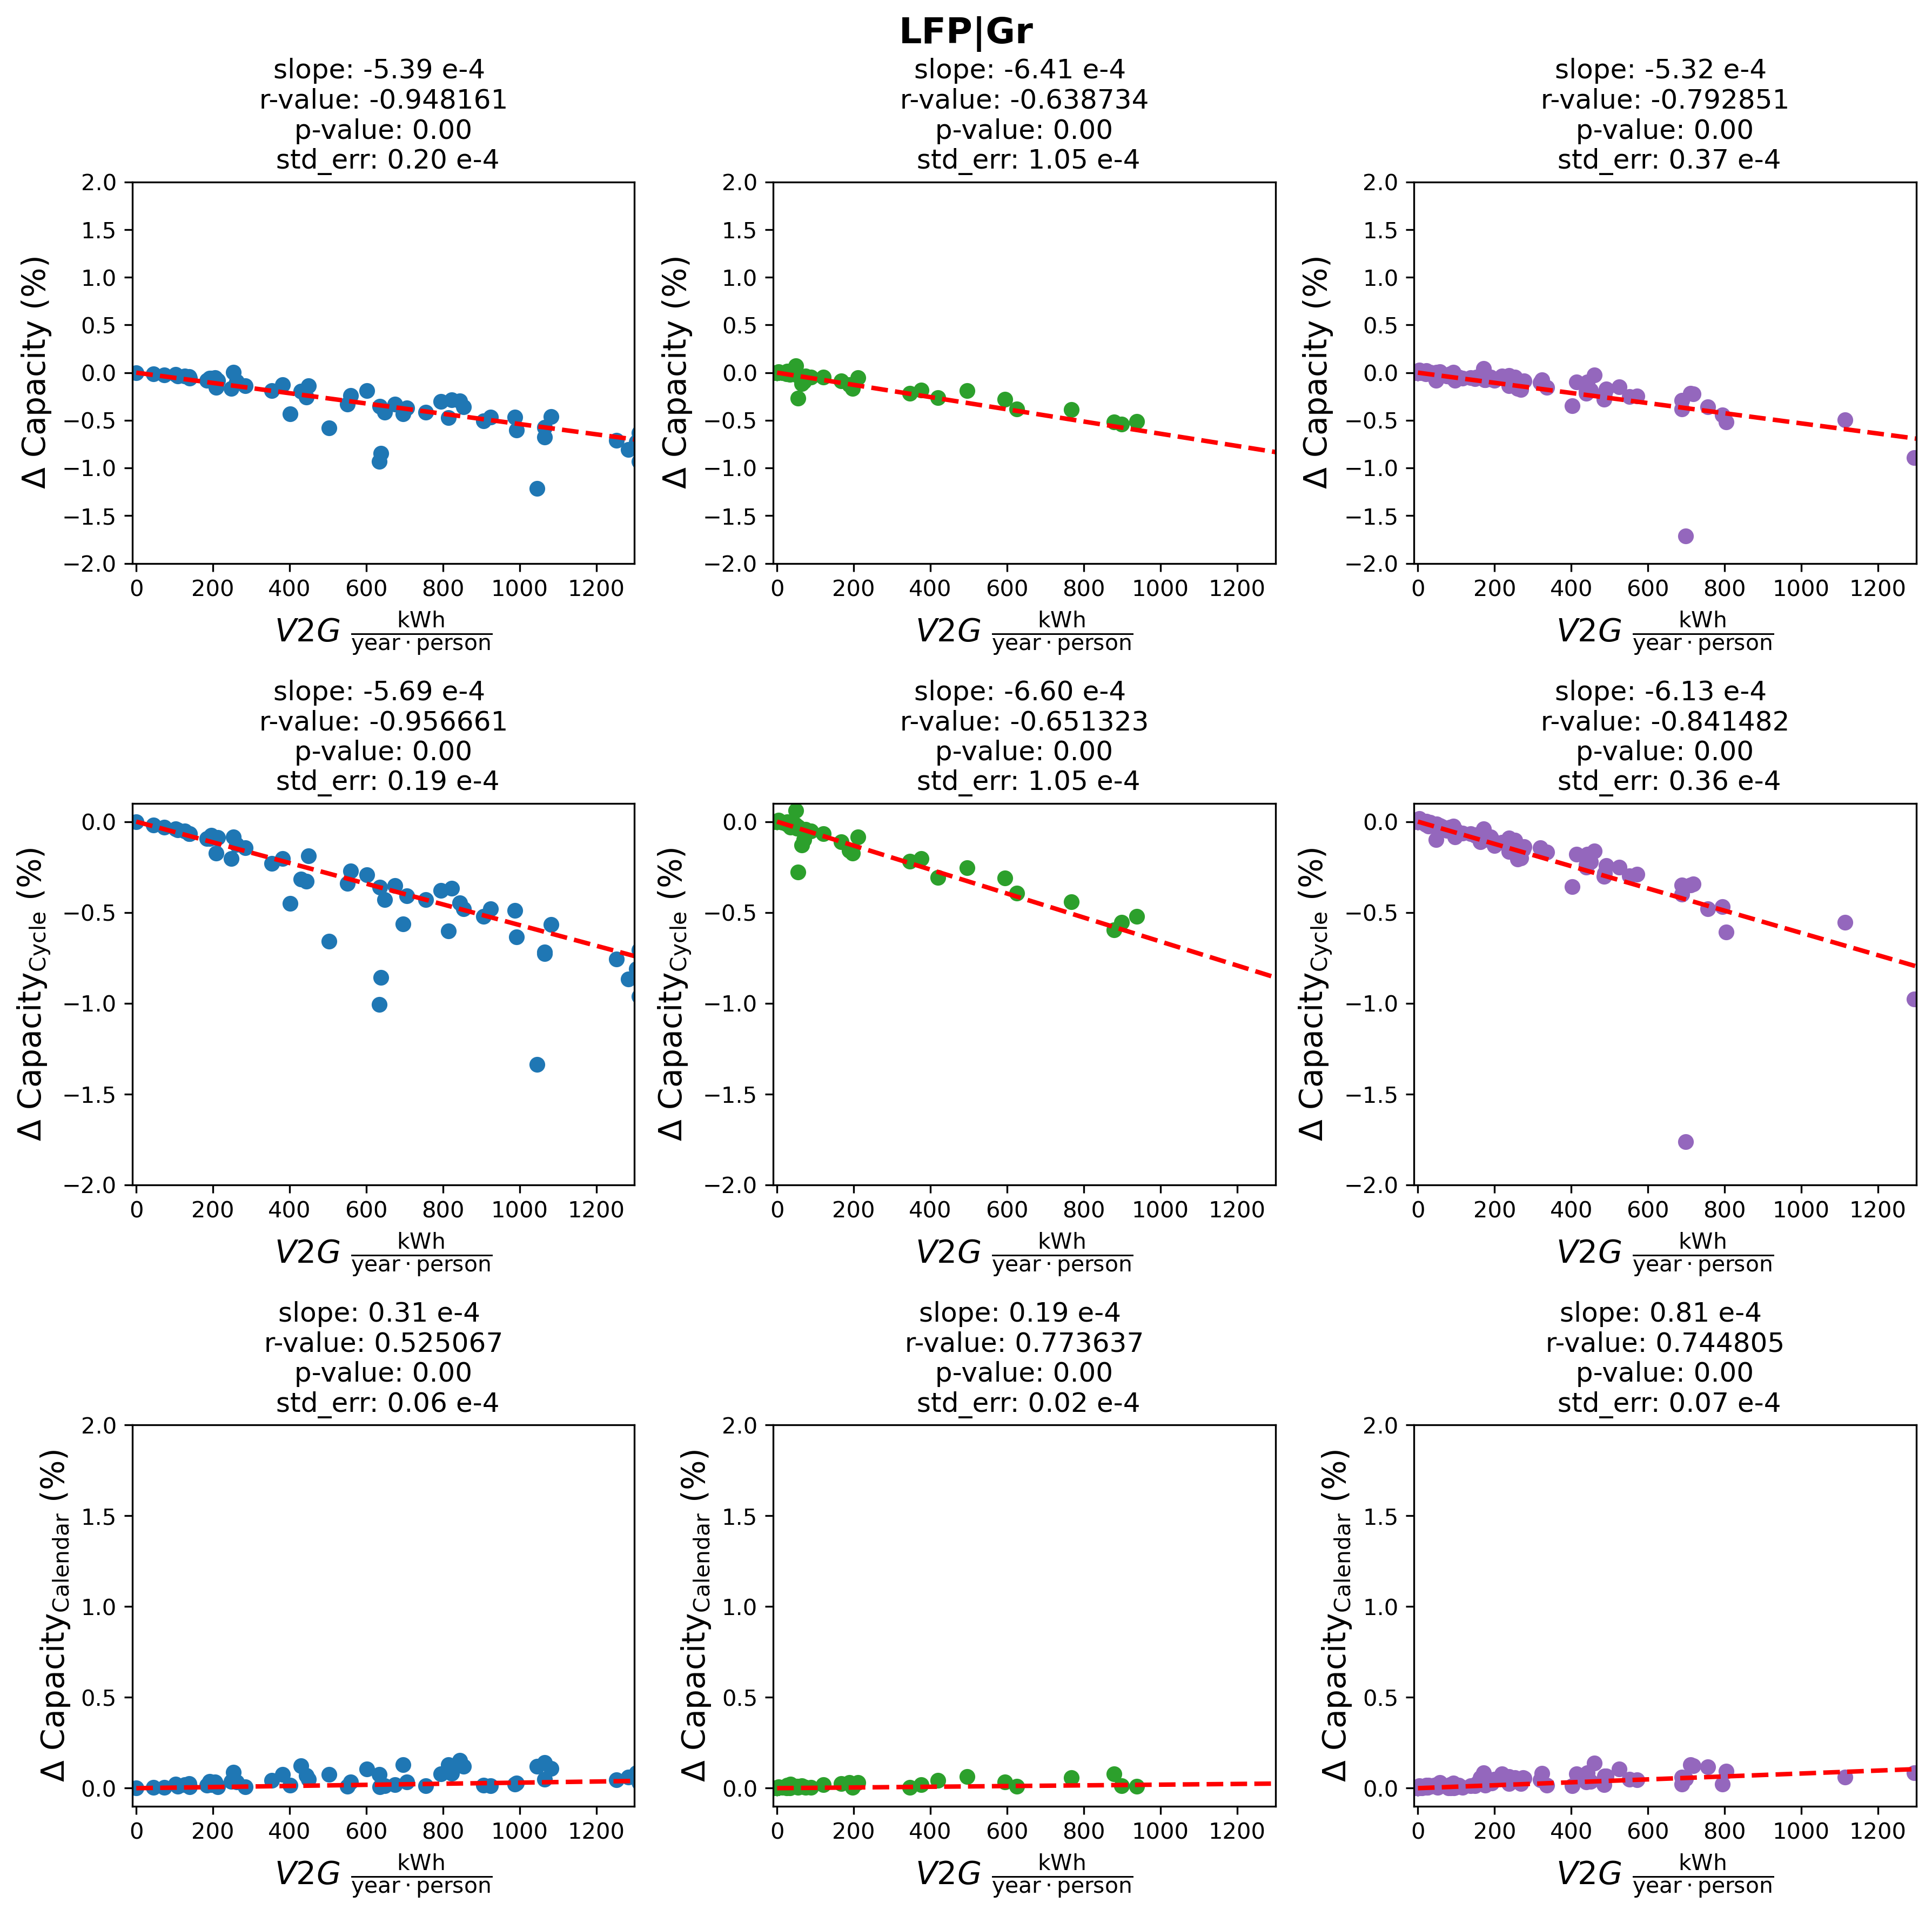

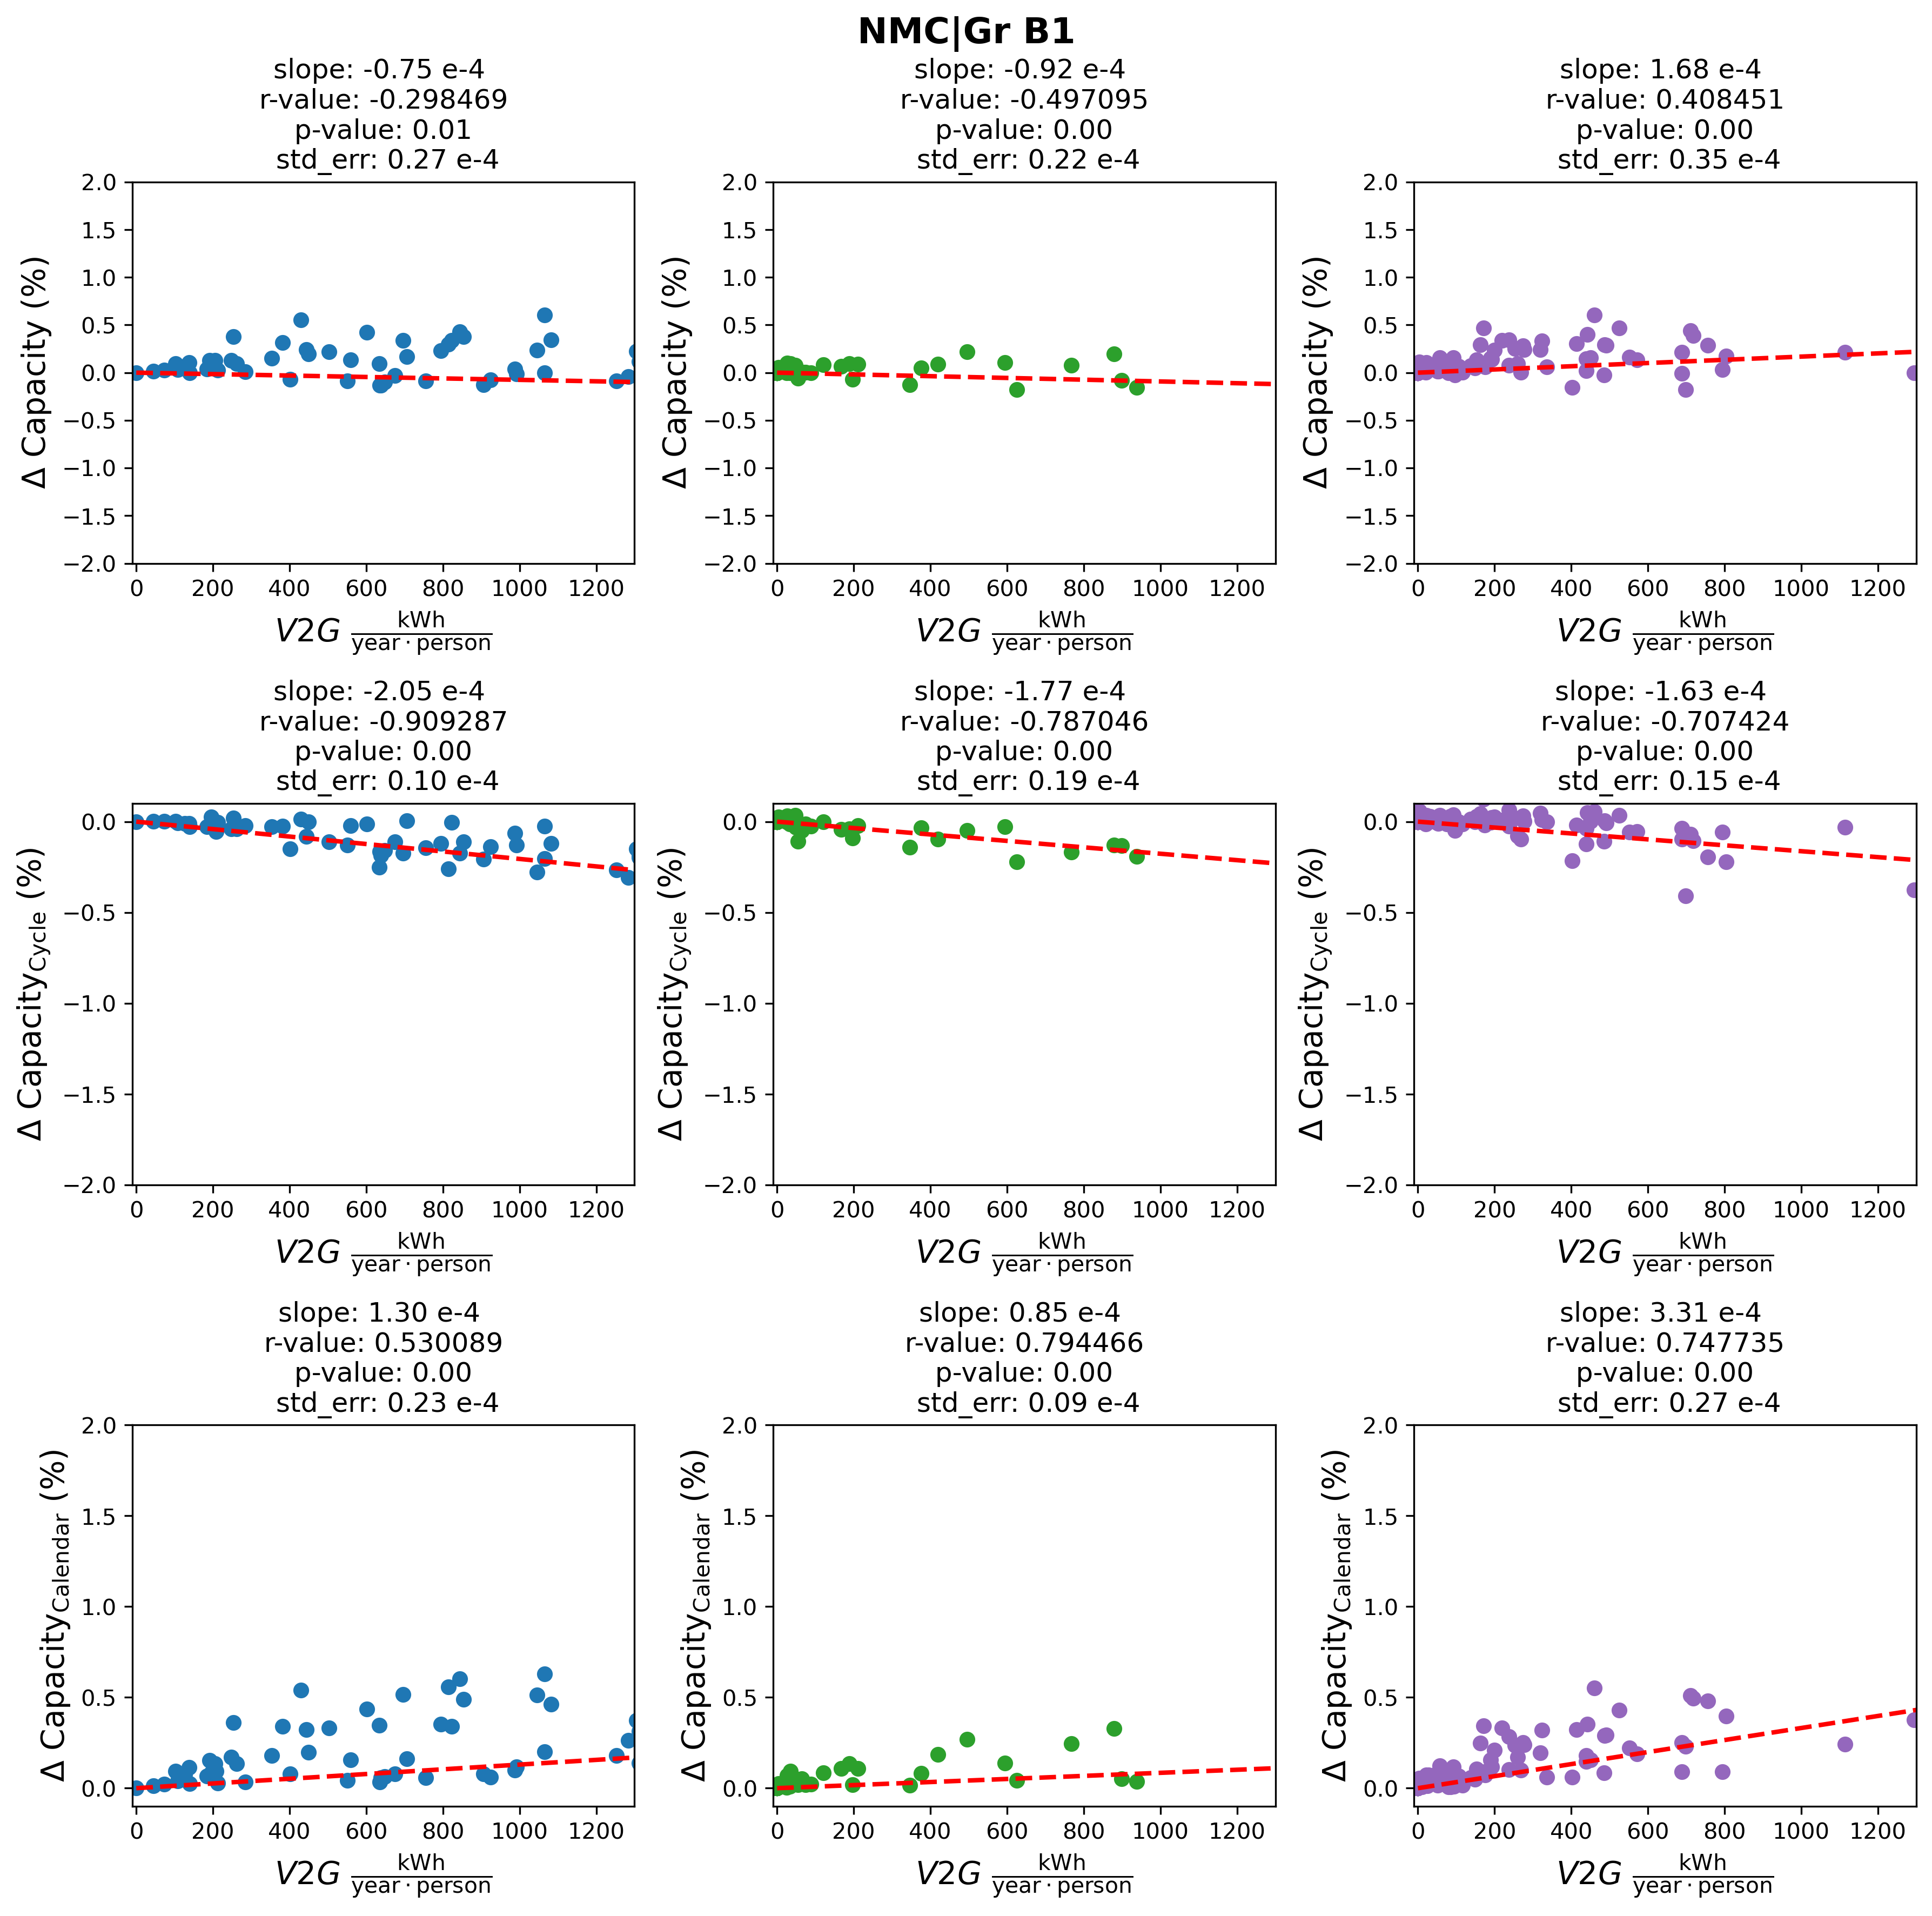

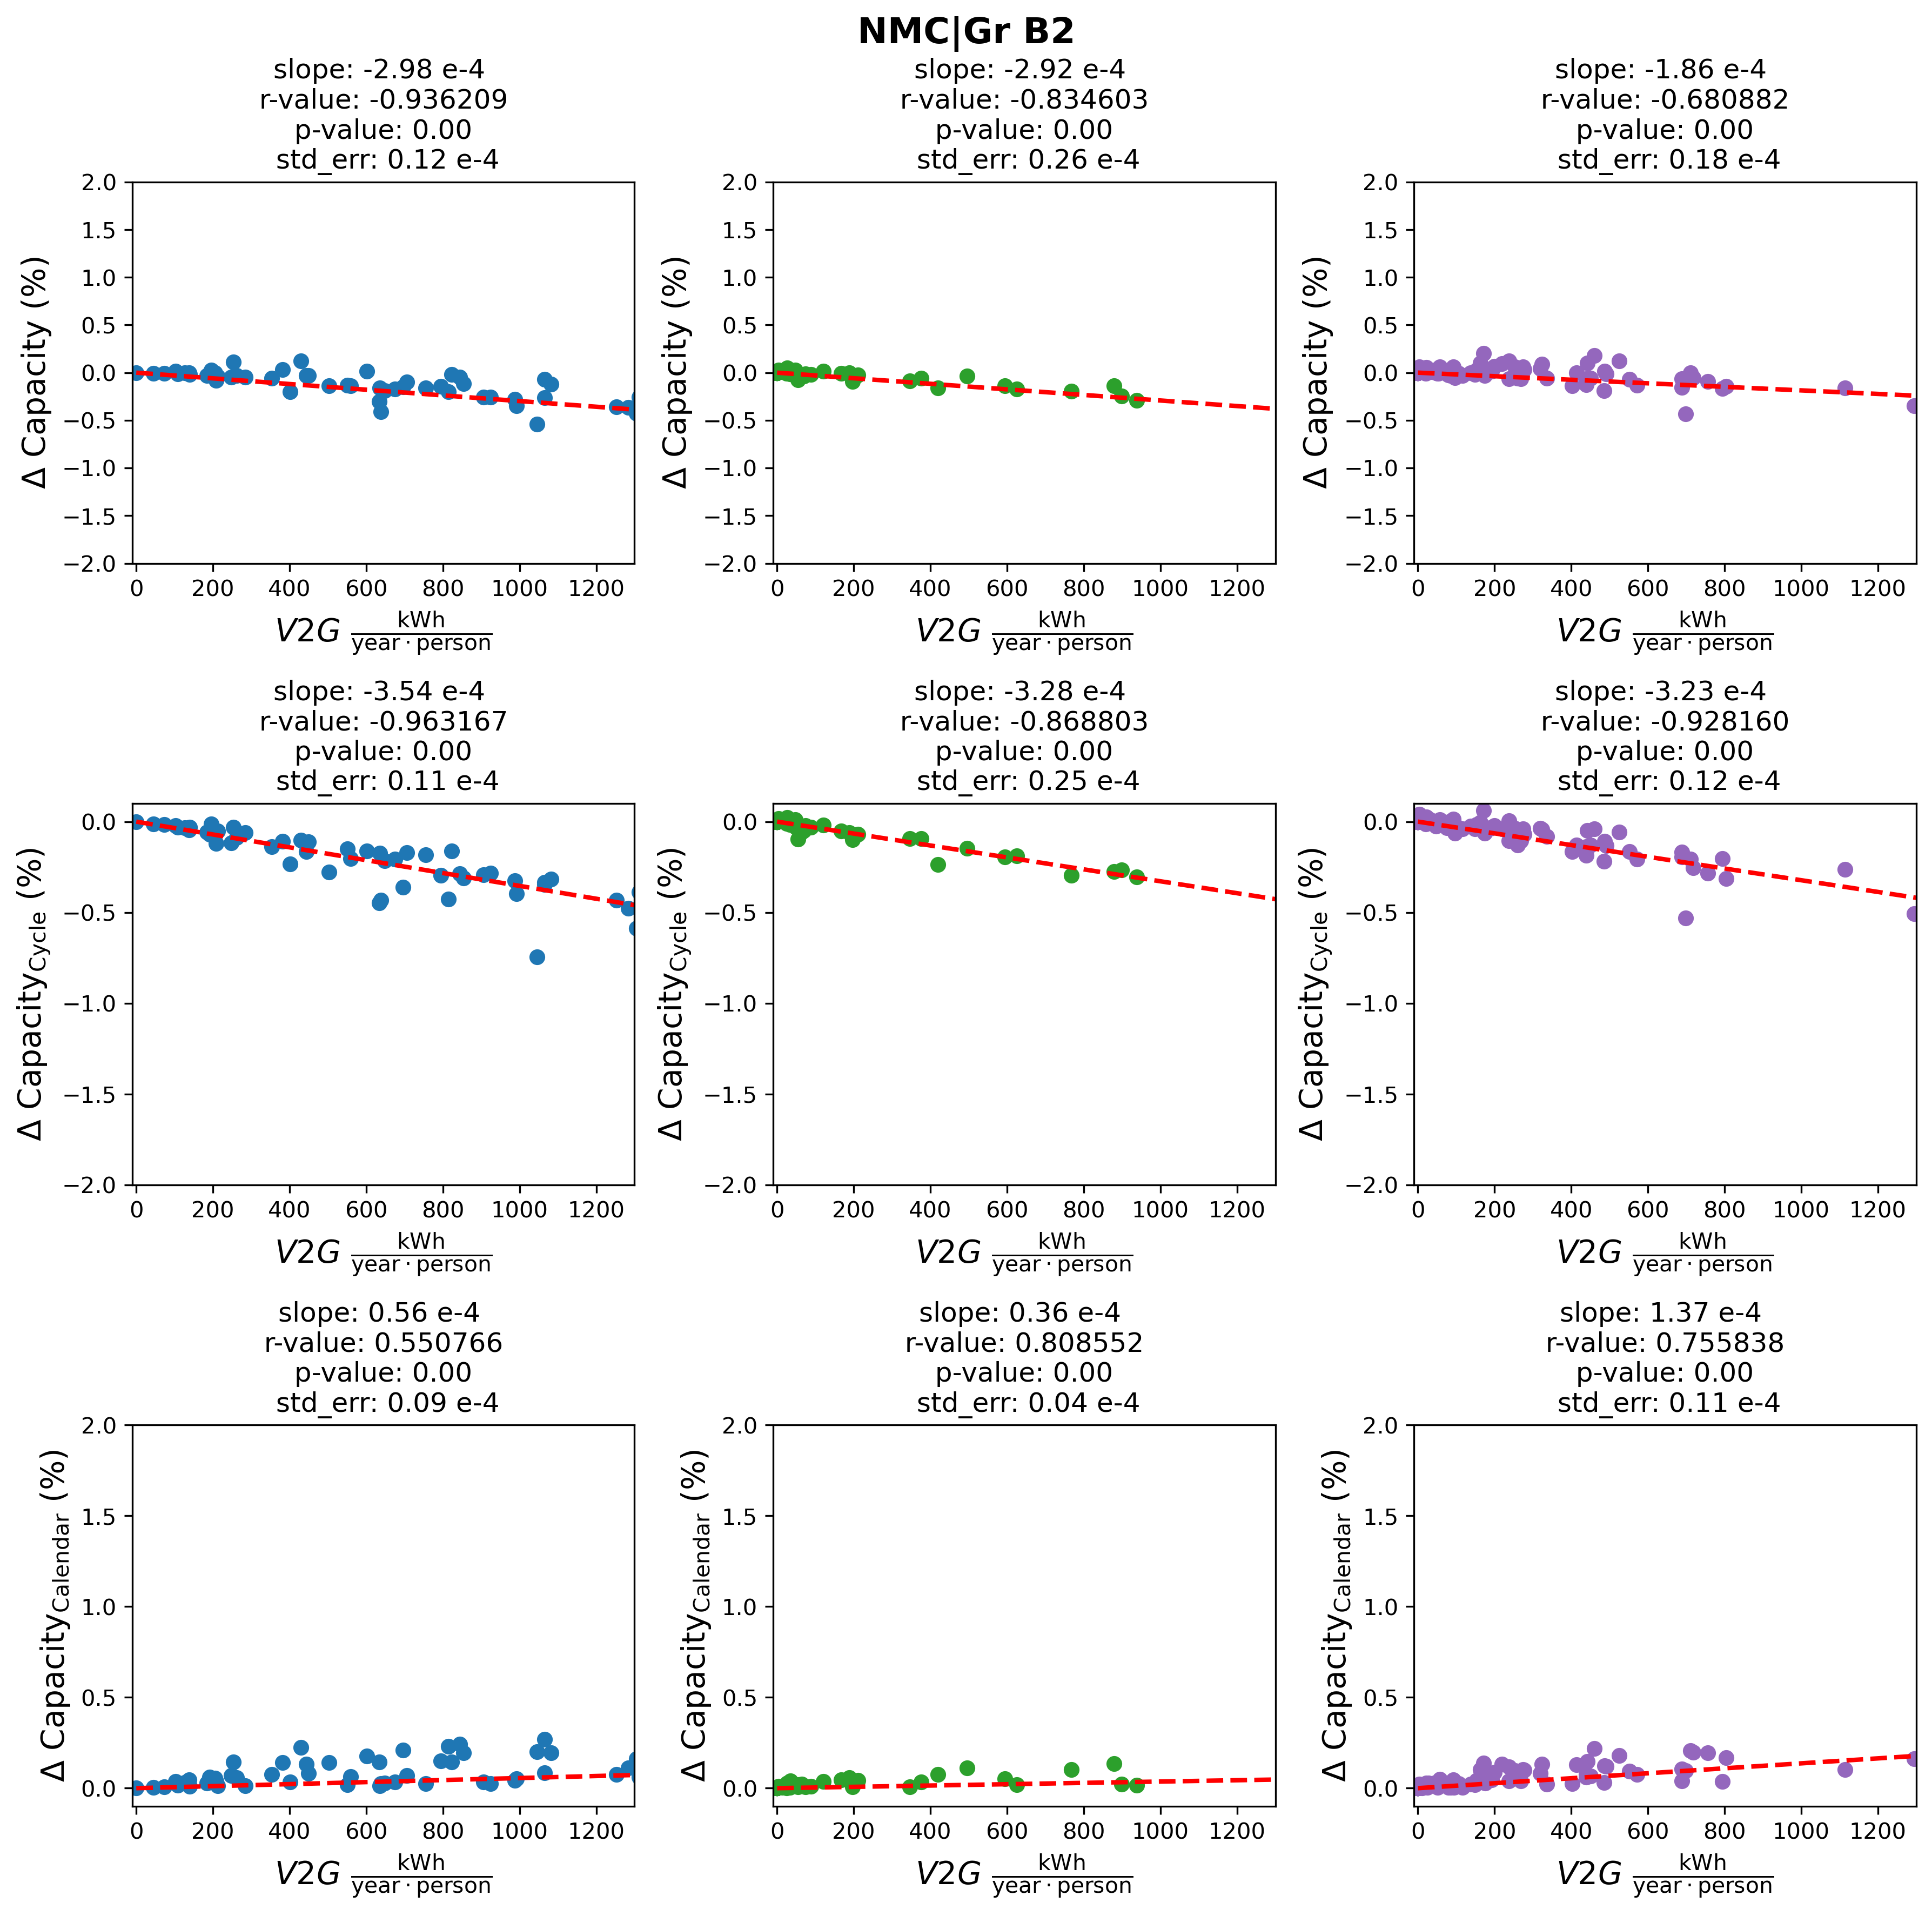

In [65]:
from scipy.stats import spearmanr

from scipy.stats import linregress

## 2. Figure: Each VIN's Delta Capacity (Capacity_{with V2G} - Capacity_{no V2G}) at year 10 for all VINs

color_dict = ({0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c', 3: '#9467bd'})

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
# Example data
chemistry_array  = ["LFP|Gr", "NMC|Gr B1", "NMC|Gr B2"]


for chemistry in chemistry_array:

    sorted_df = (
        results_df
        .sort_values(by='cluster')  # Sort by the 'cluster' row
        .groupby('cluster', group_keys=False)  # Group by 'cluster'
        .apply(lambda group: group.sort_values(by=['delta_q_loss_%s_10_years'%chemistry])))

  
  
    degradation_labels = ['delta_q_loss_%s_10_years'%chemistry, 'delta_q_loss_cyc_%s_10_years'%chemistry,'delta_q_loss_cal_%s_10_years'%chemistry]

    degradation_label_ylabel_dict ={'delta_q_loss_cyc_%s_10_years'%chemistry: "Capacity$_{\mathrm{Cycle}}$ (%)", 'delta_q_loss_cal_%s_10_years'%chemistry: "Capacity$_{\mathrm{Calendar}}$ (%)", 'delta_q_loss_%s_10_years'%chemistry : "Capacity (%)"}



    fig, ax = plt.subplots(3, 3, figsize=(12, 12),dpi=300)
    fig.suptitle(chemistry, fontweight='bold', fontsize=16)
    j =0 
    for cluster in [0,2,3]:
        cluster_sorted_df = sorted_df[sorted_df['cluster'] == cluster]
        i =0
        for degradation_label in degradation_labels: 

            ax[i,j].scatter(cluster_sorted_df ['V2G_kwh_10_years']/10,cluster_sorted_df [degradation_label],  color = color_dict[cluster])
            ax[i,j].set_xlabel(r'$V2G \ \frac{\mathrm{kWh}}{\mathrm{year} \cdot \mathrm{person}}$', fontsize=14)
            ax[i,j].set_ylabel(r'$\Delta$ %s'%degradation_label_ylabel_dict[degradation_label], fontsize=14)

            slope, intercept, r_value, p_value, std_err = linregress(cluster_sorted_df ['V2G_kwh_10_years']/10,cluster_sorted_df [degradation_label])

            
            x_max = cluster_sorted_df['V2G_kwh_10_years'].max() / 10
            x_range = np.linspace(0, x_max, 100)
            y_line = slope * x_range
            
            ax[i,j].plot(x_range, y_line, 'r--', linewidth=2)

            # correlation, p_value = spearmanr(cluster_sorted_df ['V2G kwh']/10,-cluster_sorted_df [degradation_label])

            ax[i,j].set_title('slope: %.2f e-4 \n r-value: %f \n p-value: %.2f \n std_err: %.2f e-4'%( slope*10000, r_value, p_value, std_err*10000 ), fontsize=12)



            ax[i,j].set_xlim([-10, 1300])
            i = i+1



        ax[0,j].set_ylim(-2, 2)

        ax[1,j].set_ylim(-2, .1)

        ax[2,j].set_ylim(-.1, 2)
        j= j+1

          # Show the plot
        fig.tight_layout(pad=1)
        fig.show()


